# 05_followup_fix_dev.ipynb — Detach-Hydra fix development run: choose at most one overfitting fix

**Author:** Shreed

**Notebook:** `02_detach_hydra/notebooks/05_followup_fix_dev.ipynb`. It follows `04_followup_fix_pilot.ipynb`.

## Background, in plain words

- **Detach-Hydra v2** trains the full Hydra and then removes whole kernel groups. Its group ranking is averaged over 5 stratified 80 % subsamples of the training set. On the 72 held-out datasets it beat a fresh smaller Hydra (`small_g`) at 1/16 of the kernels by +1.22 pp.
- **Its ranking can overfit** on noisy datasets with few classes: a group that happens to fit noise in the training data looks important.
- **The fix pilot** tried two fixes on 6 development datasets, chosen as v1's 3 worst and 3 best cases:
  - **Fix A (`detach_v2A`):** rank over 20 subsamples of 50 % instead of 5 of 80 %.
  - **Fix D (`detach_v2_hybrid`):** keep half the budget by ranking and spread the other half evenly over every (dilation, input) block.
  - Both roughly halved the damage on the failure datasets but gave up some advantage at 1/16. Because the 6 datasets were picked as extremes, part of that effect may be regression to the mean.
- **This notebook** runs v2, Fix A and Fix D on the **other 34 development datasets**, which were not picked as extremes. A **choice rule fixed in advance** (the next-but-one cell, written before any results) decides whether to adopt **at most one** fix or to keep v2.
- **This is a development decision, not a confirmation.** All 40 development datasets were used to design Detach, so whatever is chosen here cannot be claimed as "confirmed better than v2" without fresh data.

## Run guide

| Setting | Meaning |
|---|---|
| `QUICK_RUN = False` | the real run: 34 datasets × 5 splits (170 pairs) |
| `QUICK_RUN = True` | smoke test: ItalyPowerDemand and Plane × resample 0; every output file is prefixed `quick_` |
| `INCLUDE_V1 = False` | optional `detach_v1` reference on the cached features (adds one cheap path per pair) |

**Outputs** (in `02_detach_hydra/results/`): `detach_fix_dev_runs.csv`, `detach_fix_dev_paths.csv`, `detach_fix_dev_rankings.csv`, `detach_fix_dev_kept_groups.csv`, `detach_fix_dev_failures.csv` (only if something fails), and figures prefixed `detach_fix_dev_` (in `02_detach_hydra/results/figures/`).

**Resumable.** Rows are appended after every (dataset, resample) pair, with `runs` written last as the completion marker. If the run stops, run the same command again: completed pairs are skipped and partial rows of an interrupted pair are dropped.

**Headless overnight run** (from the repo root; `caffeinate -i` keeps the Mac awake):

```
nohup caffeinate -i hydra_env/bin/jupyter nbconvert --to notebook --execute --inplace \
    --ExecutePreprocessor.timeout=-1 02_detach_hydra/notebooks/05_followup_fix_dev.ipynb \
    > 02_detach_hydra/results/detach_fix_dev_log.txt 2>&1 &
```

`hydra_env` needs `nbconvert` once (`hydra_env/bin/pip install nbconvert`), or register it as a kernel (`hydra_env/bin/python -m ipykernel install --user --name hydra_env`) and use anaconda's nbconvert with `--ExecutePreprocessor.kernel_name=hydra_env`. Follow progress with `tail -f 02_detach_hydra/results/detach_fix_dev_log.txt`. With `--inplace` the outputs are saved into the notebook only when execution finishes; the CSVs are written after every pair.

**Expected runtime and memory:** about 4–5 h. The decisive run took about 150 min on these 34 datasets, of which FordA and FordB took about 40 min each. Here each pair adds a v2 path (about 3–4× the v1 path) and a v2A path (about 2× v2), but runs fewer final fits (no random draws). FordA and FordB (n_train ≈ 3,600) dominate: probably about 70–80 min each. Peak memory is about 2–3 GB, at FordA/FordB (ridge fits on about 3,600 × 6,144 features in float64).

## Pre-registered choice rule (fixed before any results exist)

**Data for the decision:** the 34 non-pilot development datasets only. Per-dataset accuracy is averaged over the 5 splits (and over the 3 seeds for `small_g`). Let Δ_M(b) = accuracy of method M − accuracy of `small_g` at budget b, per dataset. "Small budgets" means b ∈ {0.25, 0.125, 0.0625}.

**Why not the earlier "fewer datasets losing > 5 pp" rule.** In the decisive run none of these 34 datasets lost more than 5 pp to `small_g`; all the large failures were in the pilot set. That count would be 0 for every method and could not decide anything. The rule therefore uses the **average downside**, which counts every loss but treats wins as zero.

**Quantities, for M ∈ {v2, v2A, v2_hybrid}:**
- **Downside** `D(M)` = mean over the 34 datasets and the 3 small budgets of `min(0, Δ_M(b))`, in pp. It is 0 when M never loses to `small_g`, and more negative the bigger the losses.
- **Advantage at 1/16** `A16(M)` = mean over the 34 datasets of `Δ_M(0.0625)`, in pp.
- **Overall** `O(M)` = mean over the 34 datasets and the 3 small budgets of (accuracy of M − accuracy of v2), in pp.

**A fix F ∈ {v2A, v2_hybrid} is eligible if all three hold:**
1. `reduces_downside`: `D(F) ≥ D(v2) + 0.10` (the losses shrink by at least 0.1 pp on average);
2. `keeps_1_16_advantage`: `A16(F) ≥ A16(v2) − 0.30`;
3. `not_worse_overall`: `O(F) ≥ −0.10`.

**Decision:**
- If no fix is eligible: **keep v2**.
- If exactly one is eligible: adopt it.
- If both are eligible: adopt the one with the larger downside improvement `D(F) − D(v2)`. If the two improvements differ by less than 0.10 pp, adopt `v2_hybrid`, because it adds no training cost.

**Pre-declared secondary reports (descriptive; they do not change the decision):**
- the number of datasets with Δ < −2 pp and with Δ < −5 pp at any small budget, per method;
- the Wilcoxon signed-rank p for (F − v2) per budget, for information;
- the same quantities on all 40 development datasets, adding the 6 pilot datasets from `detach_fix_pilot_runs.csv`;
- path cost;
- block coverage.

**Computation notes (fixed now):** the comparisons use the numbers in pp as computed, with a tolerance of 1e-9 pp for floating-point rounding at a threshold. The decision is labelled final only if all 34 datasets have all 5 splits.

**Frozen.** This rule is fixed before the run and will not be changed after seeing results.

**Date fixed:** 2026-11-11 (before this notebook was run).

## 1. Setup

In [1]:
from pathlib import Path
import sys

# Repository root = the folder that contains hydra-authors-repo/ (works from any working directory)
ROOT = Path.cwd().resolve()
while not (ROOT / "hydra-authors-repo").exists():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("Run this notebook from inside the hydra-time-series-project repository.")
    ROOT = ROOT.parent

HYDRA_CODE  = ROOT / "hydra-authors-repo" / "code"
AUTHORS_RES = ROOT / "hydra-authors-repo" / "results"
RESULTS_DIR = ROOT / "02_detach_hydra" / "results"
FIG_DIR     = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(HYDRA_CODE))

PROJECT_DIR = ROOT
DATA_DIR = ROOT / "data" / "ucr_tsml"          # git-ignored; aeon downloads any missing dataset here
# read only; written by 01_reproduction/notebooks/01_hydra_baseline.ipynb (run that first)
BASELINE_CSV = ROOT / "01_reproduction" / "results" / "hydra_default_baseline.csv"
print("Project directory:", PROJECT_DIR.resolve())

Project directory: /Users/shreed/PROJECTS/Hydra_1


In [2]:
import gc
import importlib.util
import inspect
import json
import math
import os
import random
import sys
import traceback
import warnings
from time import perf_counter

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import wilcoxon

from aeon.datasets import load_classification
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score

# sklearn's LinAlgWarning: ridge at a small alpha with n_train << n_features gives a near-singular Gram matrix.
# sklearn warns and falls back to a least-squares solve. These are warnings, not errors; the results are still
# computed (the same filter as the decisive notebook). Filtering them keeps the progress log readable.
from scipy.linalg import LinAlgWarning
warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", message="Singular matrix in solving dual problem")
warnings.filterwarnings("ignore", message="The least populated class")

print("numpy", np.__version__, "| pandas", pd.__version__, "| torch", torch.__version__)

numpy 2.3.5 | pandas 3.0.6 | torch 2.15.0


### Settings

- **Same splits, kernels, budgets and seeds as the decisive run and the pilot**, so `full` and `small_g` reproduce the decisive run exactly (Check 9).
- `RUN_DATASETS` = the 40 development datasets minus the 6 pilot datasets (asserted: exactly 34, none held out, none a pilot dataset).
- **Methods:** `full`, `small_g`, `detach_v2`, `detach_v2A` (Fix A), `detach_v2_hybrid` (Fix D on the v2 ranking); optional `detach_v1`. A + D is not run.

In [3]:
# ===================== settings =====================
QUICK_RUN = False            # True: 2 small datasets x 1 resample, outputs prefixed quick_. False for the overnight run.
INCLUDE_V1 = False           # optional: detach_v1 on the cached features, as a reference

# The 40 development datasets, EXACTLY as in 02_development_run.ipynb
DEV_DATASETS = [
    "Beef", "BirdChicken", "Car", "CricketX", "CricketY", "CricketZ", "DistalPhalanxTW", "ECG5000",
    "FiftyWords", "Fish", "FordA", "FordB", "Haptics", "Herring", "InsectWingbeatSound",
    "ItalyPowerDemand", "LargeKitchenAppliances", "Lightning7", "Meat", "MedicalImages",
    "MiddlePhalanxOutlineAgeGroup", "MiddlePhalanxOutlineCorrect", "OSULeaf", "OliveOil", "Phoneme",
    "Plane", "ProximalPhalanxOutlineCorrect", "ProximalPhalanxTW", "ScreenType", "ShapeletSim",
    "Strawberry", "SwedishLeaf", "SyntheticControl", "ToeSegmentation1", "Trace",
    "UWaveGestureLibraryY", "Wafer", "WordSynonyms", "Worms", "Yoga",
]
assert len(DEV_DATASETS) == 40 and len(set(DEV_DATASETS)) == 40, "need 40 unique development datasets"

# Held-out = all 112 datasets of the authors' UCR results file minus the 40 development datasets (never used here)
AUTHORS_UCR112_CSV = AUTHORS_RES / "results_ucr112_hydra.csv"     # read only
UCR112 = sorted(pd.read_csv(AUTHORS_UCR112_CSV)["dataset"].astype(str).unique())
assert len(UCR112) == 112, f"expected 112 unique datasets in {AUTHORS_UCR112_CSV.name}, got {len(UCR112)}"
assert set(DEV_DATASETS) <= set(UCR112)
HELDOUT_ALL = sorted(set(UCR112) - set(DEV_DATASETS))
assert len(HELDOUT_ALL) == 72

PILOT_DATASETS = ["MiddlePhalanxOutlineAgeGroup", "Worms", "ScreenType", "WordSynonyms", "FiftyWords", "Herring"]
RUN_DATASETS_ALL = [d for d in DEV_DATASETS if d not in PILOT_DATASETS]
# Check 1 (dataset lists)
assert len(RUN_DATASETS_ALL) == 34 and len(set(RUN_DATASETS_ALL)) == 34, len(RUN_DATASETS_ALL)
assert set(RUN_DATASETS_ALL) <= set(DEV_DATASETS)
assert not set(RUN_DATASETS_ALL) & set(PILOT_DATASETS)
assert not set(RUN_DATASETS_ALL) & set(HELDOUT_ALL)
assert set(PILOT_DATASETS) <= set(DEV_DATASETS)
QUICK_DATASETS = ["ItalyPowerDemand", "Plane"]
assert set(QUICK_DATASETS) <= set(RUN_DATASETS_ALL)
RUN_DATASETS = QUICK_DATASETS if QUICK_RUN else RUN_DATASETS_ALL    # sorted by n_train x length after loading
GROUP_OF = {d: "dev34" for d in RUN_DATASETS_ALL}                    # value of the 'group' column (pilot schema)

RESAMPLES = [0] if QUICK_RUN else [0, 1, 2, 3, 4]          # 0 = default split; full-Hydra kernel seed = resample id

K = 8
G = 64                                                    # full Hydra g (groups per dilation)
BUDGETS = [0.5, 0.25, 0.125, 0.0625]                      # fraction of groups kept
SMALL_BUDGETS = [0.25, 0.125, 0.0625]                     # the decision rule's "small budgets"
SMALL_G = {0.5: 32, 0.25: 16, 0.125: 8, 0.0625: 4}         # matched fresh-Hydra g'
ALPHAS = np.logspace(-6, 6, 25)                           # every ridge fit
AUTHOR_ALPHAS = np.logspace(-3, 3, 10)                    # authors' grid: only for the ECG200 baseline check
PRUNE_FRACTION = 0.10                                     # remove 10% of active groups per step (every path)
V2_B = 5                                                  # Detach v2: number of stratified subsamples
SUBSAMPLE_FRAC = 0.8                                      # Detach v2: fraction of each class per subsample
B_A = 20                                                  # Fix A (v2A): number of stratified subsamples
FRAC_A = 0.5                                              # Fix A (v2A): fraction of each class per subsample
N_SMALLG_SEEDS = 3                                        # small_g seeds: 1000 + 10*resample_id + i
DRAW_TOL = 0.0005                                         # |delta acc| below this (0.05 pp) counts as a draw
N_BOOT = 10_000                                           # used by the verbatim compare() (CI not reported)
BATCH_SIZE = 256


def smallg_seed(resample_id, i):
    return 1000 + 10 * resample_id + i


def v2_seed_base(resample_id):
    return 10_000 + 100 * resample_id                      # subsample b (1..B) uses seed_base + b



def v2a_seed_base(resample_id):
    return 20_000 + 100 * resample_id                      # Fix A: subsample b (1..B_A) uses seed_base + b


N_THREADS = os.cpu_count()
torch.set_num_threads(N_THREADS)                          # all CPU threads

PREFIX = "quick_" if QUICK_RUN else ""
TAG = f"{PREFIX}detach_fix_dev"
RUNS_CSV = RESULTS_DIR / f"{TAG}_runs.csv"
PATHS_CSV = RESULTS_DIR / f"{TAG}_paths.csv"
RANKINGS_CSV = RESULTS_DIR / f"{TAG}_rankings.csv"
KEPT_CSV = RESULTS_DIR / f"{TAG}_kept_groups.csv"
FAIL_CSV = RESULTS_DIR / f"{TAG}_failures.csv"
FIG_PREFIX = f"{TAG}_"

# Earlier results, READ ONLY
DECISIVE_RUNS_CSV = RESULTS_DIR / "detach_decisive_runs.csv"     # full, small_g, detach (= v1) on the 40 dev datasets
PILOT_RUNS_CSV = RESULTS_DIR / "detach_fix_pilot_runs.csv"       # all methods on the 6 pilot datasets (secondary view)
assert DECISIVE_RUNS_CSV.exists() and PILOT_RUNS_CSV.exists()

PRUNED_METHODS = (["detach_v1"] if INCLUDE_V1 else []) + ["detach_v2", "detach_v2_hybrid", "detach_v2A"]
FIXES = ["detach_v2A", "detach_v2_hybrid"]                # candidates; each compared with detach_v2
DECISION_METHODS = ["detach_v2", "detach_v2A", "detach_v2_hybrid"]

CHECKS = []


def log_check(name, result="PASS"):
    CHECKS.append((name, result))
    print(f"CHECK {result}: {name}")


def set_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)




log_check(f"Check 1: dataset lists - 34 run datasets = 40 development - 6 pilot; none held out")
print(f"QUICK_RUN={QUICK_RUN} | INCLUDE_V1={INCLUDE_V1} | {len(RUN_DATASETS)} datasets | resamples {RESAMPLES} | threads {N_THREADS}")
print("outputs:", RUNS_CSV.name, PATHS_CSV.name, RANKINGS_CSV.name, KEPT_CSV.name, FAIL_CSV.name)

CHECK PASS: Check 1: dataset lists - 34 run datasets = 40 development - 6 pilot; none held out
QUICK_RUN=False | INCLUDE_V1=False | 34 datasets | resamples [0, 1, 2, 3, 4] | threads 10
outputs: detach_fix_dev_runs.csv detach_fix_dev_paths.csv detach_fix_dev_rankings.csv detach_fix_dev_kept_groups.csv detach_fix_dev_failures.csv


In [4]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 7 (unchanged) ====
# Import the authors' Hydra BY FILE PATH (pip `hydra-core` would shadow `import hydra`). Not modified.
HYDRA_SOURCE = HYDRA_CODE / "hydra.py"
assert HYDRA_SOURCE.exists(), f"Missing official implementation: {HYDRA_SOURCE}"
spec = importlib.util.spec_from_file_location("hydra_official_impl", HYDRA_SOURCE)
hydra_module = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = hydra_module
spec.loader.exec_module(hydra_module)
Hydra = hydra_module.Hydra
SparseScaler = hydra_module.SparseScaler

# Confirm the group arithmetic used for budget matching: divisor = 2, h = g // 2, groups = num_dilations * g
for L_ in [24, 96, 500, 1024]:
    for g_ in [64, 32, 16, 8, 4]:
        hy_ = Hydra(L_, k=K, g=g_, seed=0)
        assert hy_.divisor == 2 and hy_.h == g_ // 2
        assert hy_.W.shape == (hy_.num_dilations, 2, K * hy_.h, 1, 9)
        assert hy_.num_dilations * hy_.divisor * hy_.h == hy_.num_dilations * g_
    assert Hydra(L_, g=4, seed=0).num_dilations == Hydra(L_, g=64, seed=0).num_dilations   # same dilations
log_check("official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g")

CHECK PASS: official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g


### Reused, verified code

No utils module exists (`detach_hydra_fix_utils.py`, `detach_hydra_v2_utils.py` and `detach_hydra_utils.py` were all looked for), so the code verified in the fix pilot is copied verbatim from `04_followup_fix_pilot.ipynb`. Each cell names its pilot cell; the pilot's own headers name the original source.

- **Pilot cell 9**, from the decisive notebook's cell 8: `load_ucr_dataset`, `make_split`, `to_tensor`.
- **Pilot cell 10**, from the decisive notebook's cell 9: `group_feature_index`, `kept_columns`, `group_table`, `PrunedHydra`, `transform`, `assert_same`.
- **Pilot cell 11**, from the confirm notebook's cell 12: `alpha_at_edge`, `detach_path` (v1), `block_counts`, `fit_ridge`, `holm`, `compare`, `drop_incomplete`, `append_csv`.
- **Pilot cell 13**, from the confirm notebook's cell 14: `stratified_subsample` and `detach_v2_path`, with the full-ranking output.
- **Pilot cell 15:** `hybrid_select`.

Lines marked `# CHANGED:` inside these cells are the **pilot's** edits (already verified there). Edits made in **this** notebook are marked `# CHANGED (dev):`.

In [5]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 9 (unchanged) ====
# ==== Reused from 02_development_run.ipynb, cell 8 (unchanged) ====
# ---- Data loading (same checks as 01_reproduction/notebooks/01_hydra_baseline.ipynb) and stratified resampling ----
def load_ucr_dataset(dataset_name, extract_path=DATA_DIR):
    X_train, y_train = load_classification(
        name=dataset_name, split="train", extract_path=str(extract_path), return_metadata=False
    )
    X_test, y_test = load_classification(
        name=dataset_name, split="test", extract_path=str(extract_path), return_metadata=False
    )
    X_train = np.asarray(X_train, dtype=np.float32)
    X_test = np.asarray(X_test, dtype=np.float32)
    y_train = np.asarray(y_train).astype(str)
    y_test = np.asarray(y_test).astype(str)

    if X_train.ndim != 3 or X_test.ndim != 3:
        raise ValueError(f"{dataset_name}: expected 3D arrays")
    if X_train.shape[1] != 1 or X_test.shape[1] != 1:
        raise ValueError(f"{dataset_name}: expected univariate data")
    if X_train.shape[2] != X_test.shape[2]:
        raise ValueError(f"{dataset_name}: train/test lengths differ")
    if not set(np.unique(y_test)).issubset(set(np.unique(y_train))):
        raise ValueError(f"{dataset_name}: test labels include unseen classes")
    return X_train, y_train, X_test, y_test


def make_split(X_train, y_train, X_test, y_test, resample_id):
    # resample 0 = default UCR split. Otherwise pool train+test and draw a new train set with the
    # SAME per-class counts as the original train set (seeded by resample_id); the rest is the test set.
    if resample_id == 0:
        return X_train, y_train, X_test, y_test
    X = np.concatenate([X_train, X_test])
    y = np.concatenate([y_train, y_test])
    rng = np.random.RandomState(resample_id)
    classes, counts = np.unique(y_train, return_counts=True)
    train_idx = []
    for c, n_c in zip(classes, counts):
        idx_c = np.flatnonzero(y == c)
        train_idx.append(rng.choice(idx_c, size=n_c, replace=False))
    train_idx = np.sort(np.concatenate(train_idx))
    test_idx = np.setdiff1d(np.arange(len(y)), train_idx)

    assert len(np.intersect1d(train_idx, test_idx)) == 0, "train/test overlap"
    assert len(train_idx) == len(y_train) and len(test_idx) == len(y_test), "split sizes differ from default"
    assert dict(zip(*np.unique(y[train_idx], return_counts=True))) == dict(zip(classes, counts))
    return X[train_idx], y[train_idx], X[test_idx], y[test_idx]


def to_tensor(X):
    return torch.as_tensor(np.ascontiguousarray(X), dtype=torch.float32)

In [6]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 10 (unchanged) ====
# ==== Reused from 02_development_run.ipynb, cell 9 (unchanged) ====
# ---- verbatim from 01_pilot.ipynb (verified building blocks) ----
def group_feature_index(hydra):
    # (num_dilations, divisor, h, 2k) column indices into the full Hydra feature matrix.
    k, h, D, V = hydra.k, hydra.h, hydra.num_dilations, hydra.divisor
    idx = np.empty((D, V, h, 2 * k), dtype=np.int64)
    ar = np.arange(k)
    for d in range(D):
        for v in range(V):
            base = (d * V + v) * 2 * h * k
            for j in range(h):
                idx[d, v, j, :k] = base + j * k + ar              # max (soft) part
                idx[d, v, j, k:] = base + h * k + j * k + ar      # min (hard) part
    return idx


def kept_columns(hydra, keep_mask):
    # Full-matrix columns, in the exact order PrunedHydra(hydra, keep_mask) produces them.
    keep_mask = np.asarray(keep_mask, dtype=bool)
    gi = group_feature_index(hydra)
    k = hydra.k
    cols = []
    for d in range(hydra.num_dilations):
        for v in range(hydra.divisor):
            js = np.flatnonzero(keep_mask[d, v])
            if len(js) == 0:
                continue
            cols.append(gi[d, v, js, :k].ravel())   # max block of the kept groups
            cols.append(gi[d, v, js, k:].ravel())   # then min block of the kept groups
    return np.concatenate(cols) if cols else np.empty(0, dtype=np.int64)


def max_columns(hydra):
    # Columns of all max (soft) features, in full-matrix order.
    gi = group_feature_index(hydra)
    return gi[..., : hydra.k].reshape(hydra.num_dilations * hydra.divisor, -1).ravel()


def group_table(hydra):
    # One row per group in flat-id order: (flat_id, dilation_index, dilation, diff_index, group).
    rows = []
    for d in range(hydra.num_dilations):
        for v in range(hydra.divisor):
            for j in range(hydra.h):
                rows.append({
                    "flat_id": (d * hydra.divisor + v) * hydra.h + j,
                    "dilation_index": d,
                    "dilation": int(hydra.dilations[d].item()),
                    "diff_index": v,
                    "group": j,
                })
    return pd.DataFrame(rows)


class PrunedHydra(nn.Module):
    # Hydra transform that only convolves the kept groups of `full_hydra`.
    # Uses the ORIGINAL weights (no resampling) and the same dilations and paddings.
    # (d, diff_index) blocks with no kept group are skipped entirely (no convolution).

    def __init__(self, full_hydra, keep_mask):
        super().__init__()
        keep_mask = np.asarray(keep_mask, dtype=bool)
        expected = (full_hydra.num_dilations, full_hydra.divisor, full_hydra.h)
        assert keep_mask.shape == expected, f"keep_mask shape {keep_mask.shape} != {expected}"
        assert keep_mask.any(), "keep_mask keeps no groups"

        self.k = full_hydra.k
        self.divisor = full_hydra.divisor
        self.keep_mask = keep_mask.copy()
        self.blocks = []   # (diff_index, dilation, padding, h_kept, W_slice)

        k = self.k
        for d in range(full_hydra.num_dilations):
            dil = int(full_hydra.dilations[d].item())
            pad = int(full_hydra.paddings[d].item())
            for v in range(full_hydra.divisor):
                js = np.flatnonzero(keep_mask[d, v])
                if len(js) == 0:
                    continue
                rows = torch.as_tensor((js[:, None] * k + np.arange(k)[None, :]).ravel(), dtype=torch.long)
                W = full_hydra.W[d, v].index_select(0, rows).clone().contiguous()   # (h_kept*k, 1, 9)
                self.blocks.append((v, dil, pad, len(js), W))

        self.needs_diff = any(b[0] == 1 for b in self.blocks)
        self.n_groups_kept = int(keep_mask.sum())
        self.n_kernels = self.n_groups_kept * k
        self.n_features = 2 * self.n_kernels

    @property
    def weight_bytes(self):
        return sum(W.numel() * W.element_size() for (_, _, _, _, W) in self.blocks)

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        Z = []
        for batch in torch.arange(num_examples).split(batch_size):
            Z.append(self(X[batch]))
        return torch.cat(Z)

    def forward(self, X):
        num_examples = X.shape[0]
        if self.needs_diff:
            diff_X = torch.diff(X)
        Z = []
        for (v, dil, pad, h_kept, W) in self.blocks:
            _Z = F.conv1d(X if v == 0 else diff_X, W, dilation=dil, padding=pad) \
                  .view(num_examples, h_kept, self.k, -1)

            max_values, max_indices = _Z.max(2)
            count_max = torch.zeros(num_examples, h_kept, self.k)

            min_values, min_indices = _Z.min(2)
            count_min = torch.zeros(num_examples, h_kept, self.k)

            count_max.scatter_add_(-1, max_indices, max_values)
            count_min.scatter_add_(-1, min_indices, torch.ones_like(min_values))

            Z.append(count_max)
            Z.append(count_min)
        return torch.cat(Z, 1).view(num_examples, -1)


class MaxOnlyHydra(nn.Module):
    # Reference: same convolutions as full Hydra, but only the max (soft) features are kept
    # (the argmin / hard-count step is skipped).

    def __init__(self, full_hydra):
        super().__init__()
        self.full = full_hydra
        self.k, self.h, self.divisor = full_hydra.k, full_hydra.h, full_hydra.divisor
        self.n_kernels = full_hydra.num_dilations * full_hydra.divisor * full_hydra.h * full_hydra.k
        self.n_features = self.n_kernels

    @property
    def weight_bytes(self):
        return self.full.W.numel() * self.full.W.element_size()

    def batch(self, X, batch_size=256):
        num_examples = X.shape[0]
        if num_examples <= batch_size:
            return self(X)
        return torch.cat([self(X[b]) for b in torch.arange(num_examples).split(batch_size)])

    def forward(self, X):
        hy = self.full
        num_examples = X.shape[0]
        if self.divisor > 1:
            diff_X = torch.diff(X)
        Z = []
        for dilation_index in range(hy.num_dilations):
            d = hy.dilations[dilation_index].item()
            p = hy.paddings[dilation_index].item()
            for diff_index in range(self.divisor):
                _Z = F.conv1d(X if diff_index == 0 else diff_X, hy.W[dilation_index, diff_index],
                              dilation=d, padding=p).view(num_examples, self.h, self.k, -1)
                max_values, max_indices = _Z.max(2)
                count_max = torch.zeros(num_examples, self.h, self.k)
                count_max.scatter_add_(-1, max_indices, max_values)
                Z.append(count_max)
        return torch.cat(Z, 1).view(num_examples, -1)


def n_kernels_of(model):
    if isinstance(model, (PrunedHydra, MaxOnlyHydra)):
        return model.n_kernels
    return model.num_dilations * model.divisor * model.h * model.k


def weight_bytes_of(model):
    if isinstance(model, (PrunedHydra, MaxOnlyHydra)):
        return model.weight_bytes
    return model.W.numel() * model.W.element_size()


def transform(model, X_tensor, batch_size=BATCH_SIZE):
    with torch.inference_mode():
        return model.batch(X_tensor, batch_size=batch_size)


def assert_same(a, b, name):
    # Exact equality preferred, allclose(atol=1e-6) accepted. Returns which one held.
    assert a.shape == b.shape, f"{name}: shape {tuple(a.shape)} != {tuple(b.shape)}"
    if torch.equal(a, b):
        return "equal"
    max_abs = (a - b).abs().max().item()
    assert torch.allclose(a, b, atol=1e-6, rtol=0), f"{name}: NOT equivalent, max |diff| = {max_abs:.3e}"
    return f"allclose (max |diff| {max_abs:.1e})"

In [7]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 11 (unchanged) ====
# ==== Reused from 03_heldout_confirmation.ipynb, cell 12 (unchanged) ====
# ---- verbatim single functions from 02_development_run.ipynb (behaviour unchanged) ----

def alpha_at_edge(alpha, grid):
    return bool(np.isclose(alpha, grid[0]) or np.isclose(alpha, grid[-1]))


def detach_path(Ztr_s_train, ytr_train, gi_flat, budget_sizes):
    # TRAIN-ONLY by construction: receives the scaled TRAINING features and TRAINING labels only.
    # No test array is a parameter, so ranking, alpha choice and budget landing cannot see test data.
    assert Ztr_s_train.shape[0] == len(ytr_train), "path must receive training rows only"
    n_groups, two_k = gi_flat.shape
    sizes = sorted(set(int(s) for s in budget_sizes), reverse=True)
    assert all(0 < s < n_groups for s in sizes)

    active = np.arange(n_groups)
    elim_step = np.full(n_groups, np.inf)          # inf = still active
    last_score = np.zeros(n_groups)
    path, snapshots, step = [], {}, 0
    while True:
        cols = gi_flat[active].ravel()
        clf = RidgeClassifierCV(alphas=ALPHAS).fit(Ztr_s_train[:, cols], ytr_train)   # alpha re-selected (train LOO)
        coef = np.atleast_2d(clf.coef_)                                               # binary -> (1, n_features)
        assert coef.shape[1] == len(cols), f"coef_ shape {clf.coef_.shape} vs {len(cols)} columns"
        scores = np.sqrt((coef.reshape(coef.shape[0], len(active), two_k).astype(np.float64) ** 2).sum(axis=(0, 2)))
        last_score[active] = scores
        n = len(active)
        hit = n in sizes
        path.append({"step": step, "groups_active": n, "frac_groups": n / n_groups,
                     "alpha": float(clf.alpha_), "alpha_at_edge": alpha_at_edge(clf.alpha_, ALPHAS),
                     "gcv_score": float(getattr(clf, "best_score_", np.nan)),
                     "budget_reached": n / n_groups if hit else np.nan})
        if hit:
            # importance ordering of ALL groups: active first (by score), then latest-eliminated first
            order = np.lexsort((last_score, elim_step))[::-1]
            assert set(order[:n]) == set(active), "active groups must rank above eliminated ones"
            snapshots[n] = {"active": np.sort(active.copy()), "order": order.copy(), "alpha": float(clf.alpha_)}
        if n <= sizes[-1]:
            break
        next_size = max(s for s in sizes if s < n)
        n_remove = min(max(1, int(math.floor(PRUNE_FRACTION * n))), n - next_size)   # clamp onto budgets
        weakest = np.argsort(scores, kind="stable")[:n_remove]
        elim_step[active[weakest]] = step
        active = np.sort(np.delete(active, weakest))
        step += 1
    assert set(snapshots) == set(sizes), "path did not land on every budget size"
    return pd.DataFrame(path), snapshots


def block_counts(groups, h, n_blocks):
    return np.bincount(np.asarray(groups, dtype=np.int64) // h, minlength=n_blocks)


def fit_ridge(Ztr_raw, ytr, Zte_raw, yte, grid):
    # SparseScaler fitted on TRAIN ONLY; RidgeClassifierCV alpha chosen by LOO/GCV on TRAIN ONLY.
    sc = SparseScaler()
    A = sc.fit_transform(Ztr_raw).detach().cpu().numpy()
    B = sc.transform(Zte_raw).detach().cpu().numpy()
    clf = RidgeClassifierCV(alphas=grid).fit(A, ytr)
    pred = clf.predict(B)
    return {"acc": accuracy_score(yte, pred), "macro_f1": f1_score(yte, pred, average="macro", zero_division=0),
            "alpha": float(clf.alpha_), "alpha_at_edge": alpha_at_edge(clf.alpha_, grid), "n_features": int(A.shape[1])}


def holm(pvals):
    p = np.asarray(pvals, dtype=float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    idx = np.argsort(np.where(ok, p, np.inf))
    m, running = ok.sum(), 0.0
    for rank, i in enumerate(idx[:m]):
        running = max(running, min(1.0, (m - rank) * p[i]))
        out[i] = running
    return out


def compare(a, b, seed=0):
    d = (a - b).dropna()
    dpp = d.to_numpy() * 100
    rng = np.random.default_rng(seed)
    boots = rng.choice(dpp, size=(N_BOOT, len(dpp)), replace=True).mean(axis=1) if len(dpp) > 1 else np.array([np.nan])
    try:
        p = wilcoxon(d.to_numpy(), zero_method="wilcox", alternative="two-sided").pvalue if (d.abs() > 0).any() else 1.0
    except ValueError:
        p = np.nan
    return {"mean_pp": dpp.mean(), "ci_lo": np.nanpercentile(boots, 2.5), "ci_hi": np.nanpercentile(boots, 97.5),
            "median_pp": np.median(dpp), "W": int((d > DRAW_TOL).sum()), "D": int((d.abs() <= DRAW_TOL).sum()),
            "L": int((d < -DRAW_TOL).sum()), "p": p, "n": len(d)}


def drop_incomplete(csv_path, done):
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        keep = [(d, r) in done for d, r in zip(df["dataset"], df["resample"])]
        if not all(keep):
            df[keep].to_csv(csv_path, index=False)
            print(f"  removed {len(keep) - sum(keep)} partial rows from {csv_path.name}")


def append_csv(df, csv_path):
    df.to_csv(csv_path, mode="a", header=not csv_path.exists(), index=False)

## 2. Detach v2 path with full ranking, and Fix D's hybrid selection

- **`detach_v2_path`** is used for both v2 (`B=5, frac=0.8`, seeds `10_000 + 100·r + b`) and v2A (`B=20, frac=0.5`, seeds `20_000 + 100·r + b`). It also returns the full ranking of all groups: later elimination ranks higher; the final survivors are ordered by their last averaged score; remaining ties go to the higher flat index. The ranking's top `round(b·G)` groups equal the plain survivors at every budget (asserted in every pair).
- **`hybrid_select`** (Fix D): the top `N // 2` groups of the ranking, then `quota = (N − N // 2) // n_blocks` (= 16·b) best unchosen groups per block, then a global top-up so that exactly N are kept.

In [8]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 13 (unchanged; its CHANGED lines are the pilot's) ====
# ==== Reused from 03_heldout_confirmation.ipynb, cell 14; CHANGED lines are marked ====
def stratified_subsample(y, frac, seed):
    # Stratified subsample WITHOUT replacement: from each class c (sorted label order) take
    # max(1, round(frac * n_c)) of its members with np.random.RandomState(seed). Returns sorted row indices.
    # Python's round() rounds halves to even (e.g. round(0.8 * 5) = 4, round(2.5) = 2).
    y = np.asarray(y)
    rng = np.random.RandomState(seed)
    idx = []
    for c in np.unique(y):
        members = np.flatnonzero(y == c)
        n_take = max(1, int(round(frac * len(members))))
        idx.append(rng.choice(members, size=n_take, replace=False))
    return np.sort(np.concatenate(idx))


def detach_v2_path(Xtr_scaled, ytr, group_cols, budgets, B, frac, alphas, seed_base):
    # TRAINING DATA ONLY. Xtr_scaled = full-Hydra TRAIN features scaled by a SparseScaler fitted on TRAIN;
    # ytr = TRAIN labels; group_cols = (G, 2k) column indices of each group. No test array is a parameter,
    # so neither the ranking, the alpha choices nor the budget landing can see test data.
    # The full-data scores are NOT used: importance = average over B fixed stratified subsamples of the
    # per-replicate normalised group norms. With B = 1 and frac = 1.0 this is exactly detach_path (v1).
    assert Xtr_scaled.shape[0] == len(ytr), "path must receive training rows only"
    t_path = perf_counter()
    ytr = np.asarray(ytr)
    n_rows = len(ytr)
    n_groups, two_k = group_cols.shape
    size_of = {b: int(round(b * n_groups)) for b in budgets}
    sizes = sorted(set(size_of.values()), reverse=True)
    assert all(0 < s < n_groups for s in sizes)

    subsamples = [stratified_subsample(ytr, frac, seed_base + b) for b in range(1, B + 1)]   # fixed for the path

    active = np.arange(n_groups)
    elim_step = np.full(n_groups, np.inf)   # CHANGED: track the step at which each group is removed (inf = survivor)
    last_score = np.zeros(n_groups)         # CHANGED: last averaged score of each group (for the full ranking)
    snapshots, log, step = {}, [], 0
    while True:
        t_step = perf_counter()
        cols = group_cols[active].ravel()
        X_act = Xtr_scaled[:, cols]
        avg = np.zeros(len(active), dtype=np.float64)
        chosen = []
        for idx in subsamples:
            if len(idx) == n_rows:              # the whole training set (frac = 1): rows used as-is, as in v1
                Xs, ys = X_act, ytr
            else:
                Xs, ys = X_act[idx], ytr[idx]
            clf = RidgeClassifierCV(alphas=alphas).fit(Xs, ys)                 # alpha re-selected (train LOO)
            coef = np.atleast_2d(clf.coef_)                                      # binary -> (1, n_features)
            assert coef.shape[1] == len(cols), f"coef_ shape {clf.coef_.shape} vs {len(cols)} columns"
            s = np.sqrt((coef.reshape(coef.shape[0], len(active), two_k).astype(np.float64) ** 2).sum(axis=(0, 2)))
            total = s.sum()
            avg += s / total if total > 0 else np.full(len(active), 1.0 / len(active))   # normalise to sum 1
            chosen.append(float(clf.alpha_))
        avg /= len(subsamples)
        last_score[active] = avg                # CHANGED: remember the averaged score of every active group

        n = len(active)
        hit = n in sizes
        if hit:
            snapshots[n] = np.sort(active.copy())
        la = np.log10(chosen)
        entry = {"step": step, "groups_active": n, "frac_groups": n / n_groups,
                 "alpha_log10_mean": float(la.mean()), "alpha_log10_std": float(la.std()),
                 "alpha_min": float(min(chosen)), "alpha_max": float(max(chosen)),
                 "frac_alpha_edge": float(np.mean([alpha_at_edge(a, alphas) for a in chosen])),
                 "budget_reached": n / n_groups if hit else np.nan}
        if n <= sizes[-1]:
            entry["step_s"] = perf_counter() - t_step
            log.append(entry)
            break
        next_size = max(s_ for s_ in sizes if s_ < n)
        n_remove = min(max(1, int(math.floor(PRUNE_FRACTION * n))), n - next_size)   # clamp onto budgets
        weakest = np.lexsort((active, avg))[:n_remove]    # lowest score first; ties -> lower flat index first
        elim_step[active[weakest]] = step        # CHANGED: record the elimination step
        active = np.sort(np.delete(active, weakest))
        entry["step_s"] = perf_counter() - t_step
        log.append(entry)
        step += 1

    assert set(snapshots) == set(sizes), "path did not land on every budget size"
    masks = {}
    for b in budgets:
        m = np.zeros(n_groups, dtype=bool)
        m[snapshots[size_of[b]]] = True
        masks[b] = m
    # CHANGED: full ranking of ALL groups, the same rule as detach_path's snapshot order in the decisive notebook:
    # later elimination ranks higher; survivors (elim_step = inf) first, ordered by their last averaged score;
    # remaining exact ties -> higher flat index first (lexsort ascending, then reversed).
    order = np.lexsort((last_score, elim_step))[::-1]                                  # CHANGED
    assert set(order[:sizes[-1]]) == set(snapshots[sizes[-1]]), "survivors must rank first"   # CHANGED
    return masks, pd.DataFrame(log), perf_counter() - t_path, order   # CHANGED: also returns the ranking



# ---- Check 7: no test data can reach the path or selection functions (signature checks) ----
# ---- no test data can reach the path functions (signature checks) ----
V2_PARAMS = list(inspect.signature(detach_v2_path).parameters)
assert V2_PARAMS == ["Xtr_scaled", "ytr", "group_cols", "budgets", "B", "frac", "alphas", "seed_base"], V2_PARAMS
assert not any("test" in p or p.startswith("Xte") or p.startswith("yte") for p in V2_PARAMS)
assert list(inspect.signature(detach_path).parameters) == ["Ztr_s_train", "ytr_train", "gi_flat", "budget_sizes"]
log_check(f"Check 7: detach_v2_path and detach_path take training arrays only (v2 parameters: {V2_PARAMS})")   # CHANGED: wording

CHECK PASS: Check 7: detach_v2_path and detach_path take training arrays only (v2 parameters: ['Xtr_scaled', 'ytr', 'group_cols', 'budgets', 'B', 'frac', 'alphas', 'seed_base'])


In [9]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 15 (unchanged) ====
def hybrid_select(ranking, block_of_group, N, n_blocks, quota=None, shape=None):
    # Fix D. Pure function: ranking (G,) = all group ids, most important first; block_of_group (G,) = block id
    # of each group; N = groups to keep. Returns a boolean keep mask (flat, or reshaped to `shape`).
    ranking = np.asarray(ranking, dtype=np.int64)
    block_of_group = np.asarray(block_of_group, dtype=np.int64)
    n_groups = len(ranking)
    assert np.array_equal(np.sort(ranking), np.arange(n_groups)), "ranking must be a permutation of all groups"
    assert block_of_group.shape == (n_groups,) and block_of_group.min() >= 0 and block_of_group.max() < n_blocks
    assert 0 < N <= n_groups, (N, n_groups)
    n_rank = N // 2
    if quota is None:
        quota = (N - n_rank) // n_blocks
    assert quota >= 0

    chosen = np.zeros(n_groups, dtype=bool)
    chosen[ranking[:n_rank]] = True                                  # 1. ranking half
    rank_block = block_of_group[ranking]                             # block of each ranked position
    for blk in range(n_blocks):                                      # 2. even half
        free = ranking[(rank_block == blk) & ~chosen[ranking]]       # this block's unchosen groups, best first
        chosen[free[:quota]] = True
    short = N - int(chosen.sum())                                    # 3. shortfall -> next globally ranked
    if short > 0:
        chosen[ranking[~chosen[ranking]][:short]] = True
    assert int(chosen.sum()) == N, (int(chosen.sum()), N)
    return chosen.reshape(shape) if shape is not None else chosen


HYB_PARAMS = list(inspect.signature(hybrid_select).parameters)
assert HYB_PARAMS == ["ranking", "block_of_group", "N", "n_blocks", "quota", "shape"], HYB_PARAMS
log_check("Check 7: hybrid_select takes a ranking and block ids only (no data arrays)")

CHECK PASS: Check 7: hybrid_select takes a ranking and block ids only (no data arrays)


## 3. Checks before the loop (the notebook stops on any failure)

| # (this notebook) | Check | Cell |
|---|---|---|
| 1 | Dataset lists: exactly 34 run datasets, all development, none pilot or held out | settings |
| 2 | v2 generalises v1: `detach_v2_path(B=1, frac=1.0)` gives the same kept masks **and** full ranking as `detach_path` (ECG200, Beef, seed 0) | pilot cell 22, logged as "Check 2" |
| 3 | Hybrid selection: the pilot's synthetic unit tests (exact N, top N/2 included, block quota, shortfall case, determinism, independent implementation, `quota = 0` = global top N), plus `quota = 0` on one real v2 path | pilot cell 17 (logged as "Check 4 (synthetic)") and the real-path cell |
| 4 | Subsampler at frac 0.8 and 0.5 (and 1.0): sizes `max(1, round(frac·n_c))`, every class present, deterministic, single-member class; repeated on every run split's training labels at frac 0.5 | pilot cell 23 (logged as "Check 3") and the loading cell |
| 5 | Baseline: ECG200 seed 0, authors' grid, 0.8700 | pilot cell 21 (logged under its original name) |
| 6 | Rebuild equivalence for the `detach_v2_hybrid` mask at 0.125 (before the loop on one dataset; in the loop on every dataset's first resample) | real-path cell and loop |
| 7 | Every pruned row keeps `round(b·G)` groups; every hybrid row has ≥ 16·b groups per block | loop |
| 8 | Path and selection functions receive training arrays or rankings only | signature checks plus call-site asserts |
| 9 | Reproducibility: `full` and every `small_g` seed equal `detach_decisive_runs.csv` (and `detach_v1` = decisive `detach` if enabled) | after the loop |

The copied cells keep the log messages of the notebook they came from, so the numbers printed by some of them differ from the "#" column. The table maps them. The pilot's verbatim equivalence Tests 1–4 also run, on ECG200 and Beef; these two datasets are used only for checks.

In [10]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 17 (unchanged) ====
# ---- Check 4 (synthetic): hybrid selection unit tests. No data, no model. ----
def _reference_hybrid(ranking, block_of_group, N, n_blocks, quota=None):
    # Independent, loop-based implementation of the same specification (used only to cross-check).
    ranking = [int(g) for g in ranking]
    n_rank = N // 2
    q = (N - n_rank) // n_blocks if quota is None else quota
    chosen = list(ranking[:n_rank])
    taken = set(chosen)
    per_block = {blk: 0 for blk in range(n_blocks)}
    for g in ranking:                                  # walk the ranking once, filling each block's quota
        blk = int(block_of_group[g])
        if g not in taken and per_block[blk] < q:
            chosen.append(g); taken.add(g); per_block[blk] += 1
    for g in ranking:                                  # shortfall: next globally ranked
        if len(chosen) >= N:
            break
        if g not in taken:
            chosen.append(g); taken.add(g)
    mask = np.zeros(len(ranking), dtype=bool)
    mask[chosen] = True
    return mask


rng = np.random.default_rng(2024)
n_cases = 0
for D_ in [1, 2, 3, 5, 7, 9]:
    h_ = 32
    nb = 2 * D_
    G_ = nb * h_
    blk_of = np.arange(G_) // h_
    for trial in range(15):
        ranking = rng.permutation(G_)
        for b in BUDGETS:
            N = int(round(b * G_))
            quota = (N - N // 2) // nb
            assert quota == int(16 * b), (b, quota)                       # 8 / 4 / 2 / 1 per block
            m = hybrid_select(ranking, blk_of, N, nb)
            assert m.dtype == bool and m.shape == (G_,) and m.sum() == N   # exactly N
            assert m[ranking[: N // 2]].all()                              # ranking half always included
            counts = np.bincount(blk_of[m], minlength=nb)
            assert (counts >= quota).all()                                 # quota per block (always available here)
            assert np.array_equal(m, hybrid_select(ranking.copy(), blk_of.copy(), N, nb))   # deterministic
            assert np.array_equal(m, _reference_hybrid(ranking, blk_of, N, nb))            # matches the reference
            assert np.array_equal(hybrid_select(ranking, blk_of, N, nb, shape=(D_, 2, h_)), m.reshape(D_, 2, h_))
            m0 = hybrid_select(ranking, blk_of, N, nb, quota=0)            # quota 0 -> global top N
            top = np.zeros(G_, dtype=bool); top[ranking[:N]] = True
            assert np.array_equal(m0, top)
            n_cases += 1
        for N in rng.integers(1, G_ + 1, size=5):                          # arbitrary N, not a multiple of n_blocks
            N = int(N)
            m = hybrid_select(ranking, blk_of, N, nb)
            assert m.sum() == N and m[ranking[: N // 2]].all()
            assert np.array_equal(m, _reference_hybrid(ranking, blk_of, N, nb))
            n_cases += 1

# Shortfall case: at b = 0.5 the ranking half takes ALL 32 groups of block 0
D_, h_ = 2, 32
nb, G_ = 2 * D_, 2 * D_ * h_
blk_of = np.arange(G_) // h_
ranking = np.concatenate([np.arange(32), 32 + rng.permutation(G_ - 32)])  # block 0 ranked first
N = int(round(0.5 * G_)); quota = (N - N // 2) // nb                       # N = 64, N//2 = 32, quota = 8
m = hybrid_select(ranking, blk_of, N, nb)
counts = np.bincount(blk_of[m], minlength=nb)
assert m.sum() == N and counts[0] == 32 and (counts[1:] >= quota).all(), counts
assert np.array_equal(m, _reference_hybrid(ranking, blk_of, N, nb))
even = set()
for blk in range(1, nb):                                                   # even half of the other blocks
    even |= set(ranking[(blk_of[ranking] == blk)][:quota].tolist())
rest = [g for g in ranking if g not in set(ranking[:32].tolist()) | even][: N - 32 - len(even)]
assert set(np.flatnonzero(m)) == set(ranking[:32].tolist()) | even | set(rest)  # shortfall = next globally ranked
# Partial shortfall: 28 of block 0's groups in the ranking half -> block 0 can only give 4 more
ranking = np.concatenate([np.arange(28), 28 + rng.permutation(G_ - 28)])
m = hybrid_select(ranking, blk_of, N, nb)
assert m.sum() == N and np.array_equal(m, _reference_hybrid(ranking, blk_of, N, nb))
assert np.bincount(blk_of[m], minlength=nb).min() >= quota
print(f"hybrid_select: {n_cases} synthetic cases + 2 shortfall cases passed")
log_check("Check 4 (synthetic): hybrid gives exactly N, includes the top N//2, >= quota per block, handles the "
          "shortfall case, is deterministic, matches an independent implementation; quota = 0 -> global top N")

hybrid_select: 810 synthetic cases + 2 shortfall cases passed
CHECK PASS: Check 4 (synthetic): hybrid gives exactly N, includes the top N//2, >= quota per block, handles the shortfall case, is deterministic, matches an independent implementation; quota = 0 -> global top N


In [11]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 18 (unchanged) ====
# ---- Check 5a: pilot Test 1, verbatim ----
# Load the two test datasets once
TEST_DATA = {}
for name in ["ECG200", "Beef"]:
    Xtr, ytr, Xte, yte = load_ucr_dataset(name)
    TEST_DATA[name] = (to_tensor(Xtr), ytr, to_tensor(Xte), yte)
    print(f"{name}: train {Xtr.shape}, test {Xte.shape}")

# ---- Test 1: all groups kept == official Hydra ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    pruned_all = PrunedHydra(full, np.ones((full.num_dilations, full.divisor, full.h), dtype=bool))
    r_tr = assert_same(transform(pruned_all, Xtr_t), transform(full, Xtr_t), f"Test 1 {name} train")
    r_te = assert_same(transform(pruned_all, Xte_t), transform(full, Xte_t), f"Test 1 {name} test")
    print(f"  {name}: train {r_tr}, test {r_te}")
print("Test 1 PASS: PrunedHydra(all groups kept) reproduces the official Hydra output")
log_check('pilot Test 1 (all groups kept == official) on ECG200 + Beef')

ECG200: train (100, 1, 96), test (100, 1, 96)
Beef: train (30, 1, 470), test (30, 1, 470)
  ECG200: train equal, test equal
  Beef: train equal, test equal
Test 1 PASS: PrunedHydra(all groups kept) reproduces the official Hydra output
CHECK PASS: pilot Test 1 (all groups kept == official) on ECG200 + Beef


In [12]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 19 (unchanged) ====
# ---- Check 5b: pilot Tests 2+3, verbatim ----
# ---- Test 2: random masks -> PrunedHydra(X) == full(X)[:, kept_columns] ----
# ---- Test 3: kernel / feature counts ----
rng = np.random.default_rng(12345)
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Z_full = transform(full, Xtr_t)
    shape = (full.num_dilations, full.divisor, full.h)

    masks = {}
    for frac in [0.10, 0.30, 0.50, 0.70, 0.90]:
        m = rng.random(shape) < frac
        if not m.any():
            m.flat[rng.integers(m.size)] = True
        masks[f"random ~{int(frac * 100)}%"] = m
    # Edge cases: whole (d, diff) blocks empty, and raw-only / diff-only models
    m = rng.random(shape) < 0.5; m[0, 1, :] = False; m[-1, 0, :] = False
    masks["empty blocks"] = m
    m = np.zeros(shape, dtype=bool); m[:, 1, ::3] = True
    masks["diff-only"] = m

    for label, mask in masks.items():
        pruned = PrunedHydra(full, mask)
        cols = kept_columns(full, mask)
        Z_p = transform(pruned, Xtr_t)
        res = assert_same(Z_p, Z_full[:, cols], f"Test 2 {name} {label}")
        # Test 3
        n_kept = int(mask.sum())
        assert pruned.n_features == 2 * K * n_kept == Z_p.shape[1] == len(cols), "Test 3 feature count"
        assert pruned.n_kernels == K * n_kept, "Test 3 kernel count"
        assert sum(W.shape[0] for (*_, W) in pruned.blocks) == K * n_kept, "Test 3 weight rows"
        assert len(np.unique(cols)) == len(cols), "duplicate columns in kept_columns"
        print(f"  {name:6s} {label:14s} groups kept {n_kept:4d}/{mask.size} -> {res}")

print("Test 2 PASS: rebuilt PrunedHydra == full Hydra features[:, kept_columns] for every mask")
print("Test 3 PASS: n_features == 2k * kept groups, n_kernels == k * kept groups")
log_check('pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Beef')

  ECG200 random ~10%    groups kept   24/256 -> equal
  ECG200 random ~30%    groups kept   77/256 -> equal
  ECG200 random ~50%    groups kept  131/256 -> equal
  ECG200 random ~70%    groups kept  182/256 -> equal
  ECG200 random ~90%    groups kept  232/256 -> equal
  ECG200 empty blocks   groups kept   96/256 -> equal
  ECG200 diff-only      groups kept   44/256 -> equal
  Beef   random ~10%    groups kept   25/384 -> equal
  Beef   random ~30%    groups kept  116/384 -> equal
  Beef   random ~50%    groups kept  195/384 -> equal
  Beef   random ~70%    groups kept  272/384 -> equal
  Beef   random ~90%    groups kept  347/384 -> equal
  Beef   empty blocks   groups kept  157/384 -> equal
  Beef   diff-only      groups kept   66/384 -> equal
Test 2 PASS: rebuilt PrunedHydra == full Hydra features[:, kept_columns] for every mask
Test 3 PASS: n_features == 2k * kept groups, n_kernels == k * kept groups
CHECK PASS: pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Bee

In [13]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 20 (unchanged) ====
# ---- Check 5c: pilot Test 4, verbatim ----
# ---- Test 4: SparseScaler fitted on kept columns == fitted on all columns then subset ----
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Ztr, Zte = transform(full, Xtr_t), transform(full, Xte_t)
    mask = np.random.default_rng(7).random((full.num_dilations, full.divisor, full.h)) < 0.3
    cols = torch.as_tensor(kept_columns(full, mask))

    s_all = SparseScaler()
    A_tr = s_all.fit_transform(Ztr)[:, cols]
    A_te = s_all.transform(Zte)[:, cols]
    s_sub = SparseScaler()
    B_tr = s_sub.fit_transform(Ztr[:, cols])
    B_te = s_sub.transform(Zte[:, cols])
    assert torch.allclose(A_tr, B_tr, atol=1e-6) and torch.allclose(A_te, B_te, atol=1e-6), f"Test 4 {name}"
    print(f"  {name}: max |diff| train {(A_tr - B_tr).abs().max().item():.1e}, "
          f"test {(A_te - B_te).abs().max().item():.1e}")
print("Test 4 PASS: scaling once and subsetting columns == refitting the scaler on the kept columns")
log_check('pilot Test 4 (SparseScaler subset) on ECG200 + Beef')

  ECG200: max |diff| train 0.0e+00, test 0.0e+00
  Beef: max |diff| train 0.0e+00, test 0.0e+00
Test 4 PASS: scaling once and subsetting columns == refitting the scaler on the kept columns
CHECK PASS: pilot Test 4 (SparseScaler subset) on ECG200 + Beef


In [14]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 21 (unchanged) ====
# ---- Check 6: baseline sanity (ECG200 is a held-out dataset) ----
# ---- Baseline sanity: ECG200 seed 0 with the AUTHORS' grid reproduces 01_reproduction/notebooks/01_hydra_baseline.ipynb (0.87) ----
Xtr_t, ytr, Xte_t, yte = TEST_DATA["ECG200"]
_hy = Hydra(96, k=K, g=G, seed=0)
_sc = SparseScaler()
_clf = RidgeClassifierCV(alphas=AUTHOR_ALPHAS).fit(_sc.fit_transform(transform(_hy, Xtr_t)).numpy(), ytr)
_acc = accuracy_score(yte, _clf.predict(_sc.transform(transform(_hy, Xte_t)).numpy()))
_base = pd.read_csv(BASELINE_CSV)
_exp = float(_base.loc[(_base["dataset"] == "ECG200") & (_base["seed"] == 0), "accuracy"].iloc[0])
assert abs(_acc - _exp) < 1e-9, (_acc, _exp)
log_check(f"pipeline with authors' grid reproduces Notebook 1 on ECG200 seed 0 ({_acc:.4f})")

CHECK PASS: pipeline with authors' grid reproduces Notebook 1 on ECG200 seed 0 (0.8700)


In [15]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 22 (unchanged) ====
# ==== Adapted from 03_heldout_confirmation.ipynb, cell 20 (first part); CHANGED lines are marked ====
# ---- Check 2: v2 with B = 1, frac = 1.0 reproduces the v1 path exactly (same kept masks at every budget) ----
CHECK_FEATS = {}
for name, (Xtr_t, ytr, Xte_t, yte) in TEST_DATA.items():
    full = Hydra(Xtr_t.shape[-1], k=K, g=G, seed=0)
    Ztr = transform(full, Xtr_t)
    Ztr_s = SparseScaler().fit_transform(Ztr).detach().cpu().numpy()        # scaler fitted on train only
    gi_flat = group_feature_index(full).reshape(-1, 2 * K)
    n_groups = gi_flat.shape[0]
    sizes = [int(round(b * n_groups)) for b in BUDGETS]
    _, snaps = detach_path(Ztr_s, ytr, gi_flat, sizes)
    masks_b1, _, _, order_b1 = detach_v2_path(   # CHANGED: the path now also returns the ranking
        Ztr_s, ytr, gi_flat, BUDGETS, B=1, frac=1.0, alphas=ALPHAS, seed_base=0)
    for b, s in zip(BUDGETS, sizes):
        assert np.array_equal(np.flatnonzero(masks_b1[b]), snaps[s]["active"]), f"{name} budget {b}: v2(B=1) != v1"
    assert np.array_equal(order_b1, snaps[min(sizes)]["order"]), f"{name}: v2(B=1) ranking != v1 ranking"   # CHANGED: new assert
    CHECK_FEATS[name] = (full, Ztr_s, gi_flat)
    print(f"  {name}: G = {n_groups}, v2(B=1, frac=1) kept masks and full ranking == v1 at budgets {BUDGETS}")   # CHANGED: wording
log_check("Check 2: v2 generalises v1: B = 1, frac = 1.0 gives the same kept masks AND ranking as detach_path (ECG200, Beef)")   # CHANGED: wording

  ECG200: G = 256, v2(B=1, frac=1) kept masks and full ranking == v1 at budgets [0.5, 0.25, 0.125, 0.0625]
  Beef: G = 384, v2(B=1, frac=1) kept masks and full ranking == v1 at budgets [0.5, 0.25, 0.125, 0.0625]
CHECK PASS: Check 2: v2 generalises v1: B = 1, frac = 1.0 gives the same kept masks AND ranking as detach_path (ECG200, Beef)


In [16]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 23 (unchanged) ====
# ==== Adapted from 03_heldout_confirmation.ipynb, cell 20 (second part); CHANGED lines are marked ====
# ---- Check 3: the stratified subsampler ----
y_syn = np.array(["a"] * 10 + ["b"] * 5 + ["c"] * 1 + ["d"] * 3)
for frac in [0.8, 0.5, 1.0]:
    for seed in [0, 1, 10_001, 20_001, 20_020]:   # CHANGED: adds two v2A seeds
        idx = stratified_subsample(y_syn, frac, seed)
        assert np.array_equal(idx, stratified_subsample(y_syn, frac, seed)), "not deterministic"
        assert len(np.unique(idx)) == len(idx) and np.all(np.diff(idx) > 0), "duplicates / unsorted"
        got = dict(zip(*np.unique(y_syn[idx], return_counts=True)))
        want = {c: max(1, int(round(frac * n))) for c, n in zip(*np.unique(y_syn, return_counts=True))}
        assert got == want, (frac, seed, got, want)                  # every class present, sizes as specified
assert got["c"] == 1                                                  # single-member class kept
assert not np.array_equal(stratified_subsample(y_syn, 0.8, 1), stratified_subsample(y_syn, 0.8, 2))
assert np.array_equal(stratified_subsample(y_syn, 1.0, 5), np.arange(len(y_syn)))      # frac = 1 -> all rows
for name, (_, ytr, _, _) in TEST_DATA.items():
    idx = stratified_subsample(ytr, SUBSAMPLE_FRAC, v2_seed_base(0) + 1)
    assert set(np.unique(ytr[idx])) == set(np.unique(ytr))
    idx = stratified_subsample(ytr, FRAC_A, v2a_seed_base(0) + 1)        # CHANGED: also at frac 0.5
    assert set(np.unique(ytr[idx])) == set(np.unique(ytr))           # CHANGED
# CHANGED: explicit frac = 0.5 sizes, incl. a single-member class (round(0.5) = 0 -> max(1, 0) = 1)
assert dict(zip(*np.unique(y_syn[stratified_subsample(y_syn, 0.5, 3)], return_counts=True))) == {"a": 5, "b": 2, "c": 1, "d": 2}
log_check("Check 3: stratified subsampler (frac 0.8, 0.5, 1.0): every class present, deterministic per seed, "
          "sizes max(1, round(frac*n_c)), single-member class kept")   # CHANGED: wording

CHECK PASS: Check 3: stratified subsampler (frac 0.8, 0.5, 1.0): every class present, deterministic per seed, sizes max(1, round(frac*n_c)), single-member class kept


## 4. Load the 34 datasets

- Each dataset is loaded once (aeon `load_classification` from `data/ucr_tsml`, no extra normalisation).
- `make_split` runs for every resample (sizes, class counts, no overlap), and Check 4 is repeated on every split's training labels at frac 0.5 with the v2A seeds.
- A load failure is logged and the notebook stops; nothing is substituted.
- The datasets are sorted by `n_train × length`, ascending, so FordA, FordB, Wafer, ECG5000, Phoneme, UWaveGestureLibraryY and Yoga run last.

In [17]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 25 (CHANGED (dev) lines marked) ====
DATA, load_failures = {}, []
t0 = perf_counter()
for ds in RUN_DATASETS:
    try:
        Xa, ya, Xb, yb = load_ucr_dataset(ds)
        for r in RESAMPLES:
            _, ytr_r, _, _ = make_split(Xa, ya, Xb, yb, r)          # asserts sizes, class counts, no overlap
            for b_ in range(1, B_A + 1):                             # Check 3 on real training labels, frac 0.5
                idx = stratified_subsample(ytr_r, FRAC_A, v2a_seed_base(r) + b_)
                want = {c: max(1, int(round(FRAC_A * n))) for c, n in zip(*np.unique(ytr_r, return_counts=True))}
                assert dict(zip(*np.unique(ytr_r[idx], return_counts=True))) == want, (ds, r, b_)
        DATA[ds] = (Xa, ya, Xb, yb)
    except Exception as exc:
        load_failures.append({"dataset": ds, "resample": None, "stage": "load/split",
                              "error": f"{type(exc).__name__}: {exc}"})
        print(f"LOAD FAILED: {ds}: {exc!r}")
print(f"loaded {len(DATA)}/{len(RUN_DATASETS)} datasets in {perf_counter() - t0:.1f}s")
if load_failures:
    append_csv(pd.DataFrame(load_failures), FAIL_CSV)
    raise RuntimeError(f"{len(load_failures)} dataset(s) failed to load - logged to {FAIL_CSV.name}, not substituted")
log_check(f"make_split asserts and Check 3 (frac 0.5, v2A seeds) passed for {len(DATA)} datasets x resamples {RESAMPLES}")


def cost_of(ds):
    Xa, ya, Xb, yb = DATA[ds]
    return len(ya) * Xa.shape[-1]


RUN_ORDER = sorted(RUN_DATASETS, key=cost_of)   # CHANGED (dev): comment only - ascending n_train x length, the large datasets run last
meta = pd.DataFrame([{"dataset": ds, "group": GROUP_OF[ds], "n_train": len(DATA[ds][1]), "n_test": len(DATA[ds][3]),
                      "length": DATA[ds][0].shape[-1], "n_classes": len(np.unique(DATA[ds][1])),
                      "num_dilations": Hydra(DATA[ds][0].shape[-1], seed=0).num_dilations} for ds in RUN_ORDER])
meta["G"] = meta["num_dilations"] * G
display(meta)

loaded 34/34 datasets in 3.1s
CHECK PASS: make_split asserts and Check 3 (frac 0.5, v2A seeds) passed for 34 datasets x resamples [0, 1, 2, 3, 4]


,dataset,group,n_train,n_test,length,n_classes,num_dilations,G
0,ItalyPowerDemand,dev34,67,1029,24,2,2,128
1,ShapeletSim,dev34,20,180,500,2,6,384
2,BirdChicken,dev34,20,20,512,2,6,384
3,ToeSegmentation1,dev34,40,228,277,2,6,384
4,Beef,dev34,30,30,470,5,6,384
5,Plane,dev34,105,105,144,7,5,320
6,OliveOil,dev34,30,30,570,4,7,448
7,SyntheticControl,dev34,300,300,60,6,3,192
8,Lightning7,dev34,70,73,319,7,6,384
9,Meat,dev34,60,60,448,3,6,384


### Check 3 (real path) and Check 6 before the loop

On the cheapest run dataset (resample 0, kernel seed 0), the real **v2** path runs on the training features only:
- with `quota = 0` forced, the hybrid equals the plain v2 survivors at budgets 0.5 and 0.25;
- `PrunedHydra` rebuilt from the `detach_v2_hybrid` mask at budget 0.125 gives `torch.equal` with the full features' kept columns, on train and test.

The test split is only used to compare two feature matrices, never to choose anything.

In [18]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 27 (CHANGED (dev) lines marked) ====
CHECK_DS = RUN_ORDER[0]   # CHANGED (dev): the cheapest run dataset (the pilot used Herring)
Xtr, ytr, Xte, yte = make_split(*DATA[CHECK_DS], 0)
Xtr_t, Xte_t = to_tensor(Xtr), to_tensor(Xte)
full = Hydra(Xtr.shape[-1], k=K, g=G, seed=0)
Ztr, Zte = transform(full, Xtr_t), transform(full, Xte_t)
D, h = full.num_dilations, full.h
n_blocks, n_groups = 2 * D, 2 * D * h
gi_flat = group_feature_index(full).reshape(-1, 2 * K)
block_of_group = np.arange(n_groups) // h
Ztr_s = SparseScaler().fit_transform(Ztr).detach().cpu().numpy()          # scaler fitted on train only
assert Ztr_s.shape[0] == len(ytr) == Xtr.shape[0]                          # Check 7: training rows only
masks_A, log_A, sec_A, order_A = detach_v2_path(Ztr_s, ytr, gi_flat, BUDGETS, B=V2_B, frac=SUBSAMPLE_FRAC,   # CHANGED (dev): the v2 path
                                                alphas=ALPHAS, seed_base=v2_seed_base(0))                 # CHANGED (dev): (the hybrid is built on v2 here)
for b in BUDGETS:
    top = np.zeros(n_groups, dtype=bool); top[order_A[:int(round(b * n_groups))]] = True
    assert np.array_equal(top, masks_A[b]), f"ranking top-N != survivors at {b}"
for b in [0.5, 0.25]:
    m0 = hybrid_select(order_A, block_of_group, int(round(b * n_groups)), n_blocks, quota=0)
    assert np.array_equal(m0, masks_A[b]), f"quota=0 hybrid != plain v2 survivors at budget {b}"   # CHANGED (dev): wording
log_check(f"Check 3 (real path, {CHECK_DS} r0): hybrid with quota = 0 == plain v2 survivors at budgets 0.5 and 0.25")   # CHANGED (dev): wording

N_c = int(round(0.125 * n_groups))
mask3 = hybrid_select(order_A, block_of_group, N_c, n_blocks, shape=(D, 2, h))
assert mask3.sum() == N_c and np.bincount(block_of_group[mask3.ravel()], minlength=n_blocks).min() >= (N_c - N_c // 2) // n_blocks
pruned = PrunedHydra(full, mask3)
cols = torch.as_tensor(kept_columns(full, mask3))
assert torch.equal(transform(pruned, Xtr_t), Ztr[:, cols]), "rebuild != kept columns (train)"
assert torch.equal(transform(pruned, Xte_t), Zte[:, cols]), "rebuild != kept columns (test)"
print(f"{CHECK_DS}: G = {n_groups}, v2 path {sec_A:.1f}s, hybrid@0.125 differs from plain v2 in "   # CHANGED (dev): wording
      f"{int((mask3.ravel() != masks_A[0.125]).sum() // 2)} of {N_c} groups")
log_check(f"Check 6 (before the loop): PrunedHydra(detach_v2_hybrid mask @ 0.125) == full features[:, kept_columns] ({CHECK_DS} train+test)")   # CHANGED (dev): wording
del Ztr, Zte, Ztr_s, full, pruned

CHECK PASS: Check 3 (real path, ItalyPowerDemand r0): hybrid with quota = 0 == plain v2 survivors at budgets 0.5 and 0.25
ItalyPowerDemand: G = 128, v2 path 0.3s, hybrid@0.125 differs from plain v2 in 3 of 16 groups
CHECK PASS: Check 6 (before the loop): PrunedHydra(detach_v2_hybrid mask @ 0.125) == full features[:, kept_columns] (ItalyPowerDemand train+test)


## 5. One (dataset, resample) pair

`run_fix_pair` is the pilot's function with three marked changes: v1 is optional, there is only one hybrid (on the v2 ranking), and the in-loop rebuild check uses `detach_v2_hybrid`.

1. **full:** official `Hydra(L, k=8, g=64, seed=r)`; train and test transformed once; `fit_ridge` with `ALPHAS` (scaler fitted on train, alpha by train LOO).
2. **Paths on the scaled training features only** (call-site asserts): v2 and v2A through `detach_v2_path` (and v1 if enabled). Each path's wall-clock time, full ranking and per-step log (groups active, fraction of subsample alphas at a grid edge) are saved.
3. **Pruned models at each budget**, evaluated by column-subsetting the full features, refitting `SparseScaler` on the kept train columns and fitting ridge on the full training set: `detach_v2` (v2 survivors), `detach_v2A` (v2A survivors), `detach_v2_hybrid` (hybrid on the v2 ranking; it reuses the v2 path time).
4. **small_g:** fresh `Hydra(L, k=8, g=g′, seed=1000 + 10·r + i)`, i = 0, 1, 2.

The row schema is the pilot's.

In [19]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 29 (CHANGED (dev) lines marked) ====
RUN_COLS = ["dataset", "resample", "group", "method", "budget", "seed_or_draw", "acc", "macro_f1", "groups_kept",
            "n_kernels", "n_features", "block_coverage", "min_groups_per_block", "block_counts", "alpha",
            "alpha_at_edge", "path_s", "fit_s", "n_train", "n_test", "n_classes", "length", "num_dilations", "G",
            "pair_s"]
PATH_COLS = ["dataset", "resample", "path", "step", "groups_active", "frac_groups", "frac_alpha_edge",
             "alpha_log10_mean", "alpha_log10_std", "alpha_min", "alpha_max", "alpha", "alpha_at_edge",
             "gcv_score", "step_s", "budget_reached", "path_s"]
RANK_COLS = ["dataset", "resample", "path", "group_id", "rank", "block"]
KEPT_COLS = ["dataset", "resample", "method", "budget", "flat_id", "dilation_index", "dilation", "diff_index",
             "group", "kept"]
PATH_SPECS = [("detach_v2", V2_B, SUBSAMPLE_FRAC, v2_seed_base),      # reference, identical to Stage A
              ("detach_v2A", B_A, FRAC_A, v2a_seed_base)]             # Fix A: the SAME path function
HYBRID_OF = {"detach_v2_hybrid": "detach_v2"}   # CHANGED (dev): A + D (detach_v2A_hybrid) failed the pilot and is not run


def timed_fit(Ztr_raw, ytr, Zte_raw, yte, grid):
    t0 = perf_counter()
    res = fit_ridge(Ztr_raw, ytr, Zte_raw, yte, grid)
    return res, perf_counter() - t0


def run_fix_pair(ds, r, arrays, rebuild_check=False):
    t_pair = perf_counter()
    Xa, ya, Xb, yb = arrays
    Xtr, ytr, Xte, yte = make_split(Xa, ya, Xb, yb, r)     # sizes, class counts, no overlap
    Xtr_t, Xte_t = to_tensor(Xtr), to_tensor(Xte)
    L = Xtr.shape[-1]

    set_seeds(r)
    full = Hydra(L, k=K, g=G, seed=r)                      # full-Hydra kernel seed = resample id
    Ztr = transform(full, Xtr_t)
    Zte = transform(full, Xte_t)
    D, h = full.num_dilations, full.h
    n_blocks, n_groups = 2 * D, 2 * D * h
    gi_flat = group_feature_index(full).reshape(-1, 2 * K)
    block_of_group = np.arange(n_groups) // h              # block = 2 * dilation_index + diff_index
    gtab = group_table(full)
    assert np.array_equal(gtab["flat_id"].to_numpy(), np.arange(n_groups))
    assert np.array_equal((2 * gtab["dilation_index"] + gtab["diff_index"]).to_numpy(), block_of_group)
    sizes = {b: int(round(b * n_groups)) for b in BUDGETS}

    base = {"dataset": ds, "resample": r, "group": GROUP_OF[ds], "n_train": len(ytr), "n_test": len(yte),
            "n_classes": len(np.unique(ytr)), "length": L, "num_dilations": D, "G": n_groups}
    rows, kept_rows, path_rows, rank_rows = [], [], [], []

    def add(method, budget, seed_or_draw, res, counts, fit_s, path_s=np.nan):
        counts = np.asarray(counts)
        rows.append({**base, "method": method, "budget": budget, "seed_or_draw": seed_or_draw,
                     "groups_kept": int(counts.sum()), "n_kernels": int(K * counts.sum()),
                     "block_coverage": float((counts > 0).mean()), "min_groups_per_block": int(counts.min()),
                     "block_counts": json.dumps(counts.tolist()), "fit_s": fit_s, "path_s": path_s, **res})

    res, fs = timed_fit(Ztr, ytr, Zte, yte, ALPHAS)
    add("full", 1.0, r, res, np.full(n_blocks, h), fs)

    # ---- pruning paths: TRAINING DATA ONLY (scaler fitted on train; no test array is passed) ----
    Ztr_s = SparseScaler().fit_transform(Ztr).detach().cpu().numpy()
    masks_of, ranking_of, path_s_of = {}, {}, {}
    if INCLUDE_V1:   # CHANGED (dev): v1 is optional here; the block below is the pilot's, indented one level
        # v1 (verbatim detach_path)
        assert Ztr_s.shape[0] == len(ytr) == Xtr.shape[0]      # Check 7: training rows only
        t0 = perf_counter()
        path1, snaps = detach_path(Ztr_s, ytr, gi_flat, list(sizes.values()))
        sec1 = perf_counter() - t0
        masks1 = {}
        for b in BUDGETS:
            m_ = np.zeros(n_groups, dtype=bool); m_[snaps[sizes[b]]["active"]] = True
            masks1[b] = m_
        masks_of["detach_v1"], ranking_of["detach_v1"], path_s_of["detach_v1"] = masks1, snaps[min(sizes.values())]["order"], sec1
        path1["frac_alpha_edge"] = path1["alpha_at_edge"].astype(float)   # one fit per step -> 0 or 1
        path1.insert(0, "path", "detach_v1"); path1["path_s"] = sec1
        path_rows.append(path1)
    # v2 and v2A (the same detach_v2_path, different B / frac / seeds)
    for name, B_, frac_, seed_fn in PATH_SPECS:
        assert Ztr_s.shape[0] == len(ytr) == Xtr.shape[0]  # Check 7: training rows only
        masks, plog, sec, order = detach_v2_path(Ztr_s, ytr, gi_flat, BUDGETS, B=B_, frac=frac_,
                                                 alphas=ALPHAS, seed_base=seed_fn(r))
        masks_of[name], ranking_of[name], path_s_of[name] = masks, order, sec
        plog.insert(0, "path", name); plog["path_s"] = sec
        path_rows.append(plog)
    del Ztr_s
    for name, order in ranking_of.items():
        assert np.array_equal(np.sort(order), np.arange(n_groups)), f"{name}: ranking is not a permutation"
        for b in BUDGETS:                                   # plain survivors == top-N of the path's ranking
            assert set(np.flatnonzero(masks_of[name][b])) == set(order[:sizes[b]]), (ds, r, name, b)
        rank_rows.append(pd.DataFrame({"path": name, "group_id": order, "rank": np.arange(1, n_groups + 1),
                                       "block": block_of_group[order]}))
    # ---- Fix D: hybrid selections from the v2 and v2A rankings (no data enters hybrid_select) ----
    for hyb, src in HYBRID_OF.items():
        masks_of[hyb] = {b: hybrid_select(ranking_of[src], block_of_group, sizes[b], n_blocks) for b in BUDGETS}
        path_s_of[hyb] = path_s_of[src]

    for b in BUDGETS:
        n_b = sizes[b]
        per_block = int(round(h * b))
        assert n_b == per_block * n_blocks == D * SMALL_G[b], (ds, b, n_b, per_block, n_blocks)
        for method in PRUNED_METHODS:
            groups = np.flatnonzero(masks_of[method][b])
            assert len(groups) == n_b, (ds, r, method, b, len(groups), n_b)          # Check 6
            counts = block_counts(groups, h, n_blocks)
            if method in HYBRID_OF:
                assert counts.min() >= (n_b - n_b // 2) // n_blocks, (ds, r, method, b, counts)
            mask3 = masks_of[method][b].reshape(D, 2, h)
            cols = torch.as_tensor(kept_columns(full, mask3))
            res, fs = timed_fit(Ztr[:, cols], ytr, Zte[:, cols], yte, ALPHAS)
            assert res["n_features"] == 2 * K * n_b
            add(method, b, 0, res, counts, fs, path_s_of[method])
            kt = gtab.copy()
            kt["kept"] = masks_of[method][b]
            kt.insert(0, "budget", b); kt.insert(0, "method", method)
            kt.insert(0, "resample", r); kt.insert(0, "dataset", ds)
            kept_rows.append(kt)
            if rebuild_check and b == 0.125 and method == "detach_v2_hybrid":   # CHANGED (dev): v2_hybrid (the run method)         # Check 5 in the loop
                pruned = PrunedHydra(full, mask3)
                assert torch.equal(transform(pruned, Xtr_t), Ztr[:, cols]), f"{ds} {method} rebuild != cols (train)"
                assert torch.equal(transform(pruned, Xte_t), Zte[:, cols]), f"{ds} {method} rebuild != cols (test)"
                del pruned

        for i in range(N_SMALLG_SEEDS):
            s = smallg_seed(r, i)
            small = Hydra(L, k=K, g=SMALL_G[b], seed=s)
            assert small.num_dilations == D and small.h == per_block
            res, fs = timed_fit(transform(small, Xtr_t), ytr, transform(small, Xte_t), yte, ALPHAS)
            assert res["n_features"] == 2 * K * n_b
            add("small_g", b, s, res, np.full(n_blocks, per_block), fs)
            del small

    out = pd.DataFrame(rows)
    out["pair_s"] = perf_counter() - t_pair
    out = out.reindex(columns=RUN_COLS)

    def tag(df):
        df.insert(0, "resample", r); df.insert(0, "dataset", ds)
        return df

    paths = tag(pd.concat(path_rows, ignore_index=True)).reindex(columns=PATH_COLS)
    ranks = tag(pd.concat(rank_rows, ignore_index=True)).reindex(columns=RANK_COLS)
    kept = pd.concat(kept_rows, ignore_index=True).reindex(columns=KEPT_COLS)
    del Ztr, Zte, Xtr_t, Xte_t, full
    return out, paths, ranks, kept


def completed_pairs_in(csv_path):
    # a pair is complete once its rows are in the runs CSV (written last)
    if not csv_path.exists():
        return set()
    done = pd.read_csv(csv_path, usecols=["dataset", "resample"]).drop_duplicates()
    return set(zip(done["dataset"], done["resample"]))

## 6. The experiment (checkpointed, resumable)

- Pairs run in order of dataset cost. After each pair, `paths`, `rankings` and `kept_groups` are appended, then `runs` **last** (the completion marker). Large tensors are freed inside `run_fix_pair`, and `gc.collect()` runs after every pair.
- On restart, completed pairs are skipped and partial rows of an interrupted pair are dropped.
- Each pair runs inside `try/except`; failures go to the failures CSV. An `AssertionError` (a check failed) **stops** the run.
- The ETA is weighted by `(n_train + n_test) × length`, so it is only rough.

In [20]:
# ==== Reused from 04_followup_fix_pilot.ipynb, cell 31 (CHANGED (dev) lines marked) ====
done = completed_pairs_in(RUNS_CSV)
for _csv in [PATHS_CSV, RANKINGS_CSV, KEPT_CSV]:
    drop_incomplete(_csv, done)
todo = [(ds, r) for ds in RUN_ORDER for r in RESAMPLES if (ds, r) not in done]
print(f"{len(done)} pairs already complete, {len(todo)} to run")
t_start = perf_counter()
weight = {ds: (len(DATA[ds][1]) + len(DATA[ds][3])) * DATA[ds][0].shape[-1] for ds in RUN_ORDER}   # CHANGED (dev): cost-weighted ETA
w_total, w_done = sum(weight[ds] for ds, _ in todo), 0                                              # CHANGED (dev)
for i, (ds, r) in enumerate(todo, 1):
    t0 = perf_counter()
    try:
        out, paths, ranks, kept = run_fix_pair(ds, r, DATA[ds], rebuild_check=(r == RESAMPLES[0]))
        append_csv(paths, PATHS_CSV)
        append_csv(ranks, RANKINGS_CSV)
        append_csv(kept, KEPT_CSV)
        append_csv(out, RUNS_CSV)                         # written last = completion marker
        m = out.groupby(["method", "budget"])["acc"].mean()
        el = perf_counter() - t_start
        w_done += weight[ds]                                                                         # CHANGED (dev)
        print(f"[{el / 60:6.1f} min | ETA ~{el / w_done * (w_total - w_done) / 60:6.1f} min] {i:3d}/{len(todo)} {ds:24s} r{r} "   # CHANGED (dev): weighted ETA
              f"({perf_counter() - t0:6.1f}s; paths "                                                # CHANGED (dev): v1 optional
              f"v2 {out.loc[out.method == 'detach_v2', 'path_s'].iloc[0]:.1f}s "
              f"v2A {out.loc[out.method == 'detach_v2A', 'path_s'].iloc[0]:.1f}s) | b=0.0625: "
              + " ".join(f"{mm.replace('detach_', '')} {m[(mm, 0.0625)]:.3f}" for mm in PRUNED_METHODS + ["small_g"]),
              flush=True)
    except Exception as exc:
        append_csv(pd.DataFrame([{"dataset": ds, "resample": r, "stage": "run_fix_pair",
                                  "error": f"{type(exc).__name__}: {exc}"}]), FAIL_CSV)
        print(f"FAILED {ds} r{r}: {type(exc).__name__}: {exc}")
        traceback.print_exc()
        if isinstance(exc, AssertionError):
            raise                                         # a check failed: STOP
    gc.collect()
print(f"\nfinished in {(perf_counter() - t_start) / 60:.1f} min")
done = completed_pairs_in(RUNS_CSV)
expected = {(ds, r) for ds in RUN_ORDER for r in RESAMPLES}
print(f"complete pairs: {len(done & expected)}/{len(expected)}")
log_check("Check 6 in the loop (detach_v2_hybrid rebuild @ 0.125, first resample of every dataset), Check 7 "   # CHANGED (dev): wording
          "(groups_kept == round(b*G) and hybrid >= 16b per block, every row) and Check 8 (training rows only at every path call)")

0 pairs already complete, 170 to run
[   0.1 min | ETA ~ 200.9 min]   1/170 ItalyPowerDemand         r0 (   4.1s; paths v2 0.3s v2A 1.1s) | b=0.0625: v2 0.955 v2_hybrid 0.953 v2A 0.958 small_g 0.957
[   0.1 min | ETA ~ 208.5 min]   2/170 ItalyPowerDemand         r1 (   4.4s; paths v2 0.4s v2A 1.4s) | b=0.0625: v2 0.960 v2_hybrid 0.963 v2A 0.948 small_g 0.950
[   0.2 min | ETA ~ 200.8 min]   3/170 ItalyPowerDemand         r2 (   3.7s; paths v2 0.3s v2A 1.1s) | b=0.0625: v2 0.946 v2_hybrid 0.945 v2A 0.944 small_g 0.941
[   0.3 min | ETA ~ 198.1 min]   4/170 ItalyPowerDemand         r3 (   3.8s; paths v2 0.3s v2A 1.1s) | b=0.0625: v2 0.948 v2_hybrid 0.957 v2A 0.955 small_g 0.952
[   0.3 min | ETA ~ 197.5 min]   5/170 ItalyPowerDemand         r4 (   3.9s; paths v2 0.4s v2A 1.1s) | b=0.0625: v2 0.947 v2_hybrid 0.944 v2A 0.949 small_g 0.936
[   0.5 min | ETA ~ 159.3 min]   6/170 ShapeletSim              r0 (   8.5s; paths v2 0.3s v2A 0.9s) | b=0.0625: v2 0.994 v2_hybrid 1.000 v2A 0.994 small

## 7. Check 9: reproducibility against the decisive run

| This notebook (`method`, `budget`, `seed_or_draw`) | Decisive file label | Join keys |
|---|---|---|
| `full`, 1.0 | `method == "full"`, budget 1.0 | dataset, resample, budget |
| `small_g`, b, seed `1000 + 10·r + i` | `method == "small_g"`, column `seed` (float → int) | dataset, resample, budget, seed |
| `detach_v1`, b (only if `INCLUDE_V1`) | `method == "detach"` | dataset, resample, budget |

- Compared: `acc` (max |Δ| printed per method; it must be 0) and `groups_kept`.
- Every completed pair must find its rows in the decisive file. Budgets are joined after rounding to 6 decimals. Any mismatch prints the rows and raises.

In [21]:
ours = pd.read_csv(RUNS_CSV)
dec = pd.read_csv(DECISIVE_RUNS_CSV)
for df in (ours, dec):
    df["budget"] = df["budget"].round(6)
dec_sg = dec[dec["method"] == "small_g"].copy()
dec_sg["seed_int"] = dec_sg["seed"].round().astype(int)
ours_sg = ours[ours["method"] == "small_g"].copy()
ours_sg["seed_int"] = ours_sg["seed_or_draw"].astype(int)
MAPPING = [("full", ours[ours["method"] == "full"], dec[dec["method"] == "full"], ["dataset", "resample", "budget"]),
           ("small_g", ours_sg, dec_sg, ["dataset", "resample", "budget", "seed_int"])]
if INCLUDE_V1:
    MAPPING.append(("detach_v1", ours[ours["method"] == "detach_v1"], dec[dec["method"] == "detach"],
                    ["dataset", "resample", "budget"]))
done_pairs = set(zip(ours["dataset"], ours["resample"]))
repro_rows, problems = [], []
for method, a, b_, keys in MAPPING:
    ref_pairs = set(zip(b_["dataset"], b_["resample"]))
    if not done_pairs <= ref_pairs:
        problems.append(f"{method}: completed pairs missing from {DECISIVE_RUNS_CSV.name}: {sorted(done_pairs - ref_pairs)}")
    assert not b_.duplicated(keys).any(), f"duplicate reference rows for {keys}"
    mrg = a[keys + ["acc", "groups_kept"]].merge(b_[keys + ["acc", "groups_kept"]], on=keys, how="left",
                                                 suffixes=("", "_ref"), validate="one_to_one")
    n_unmatched = int(mrg["acc_ref"].isna().sum())
    diff = (mrg["acc"] - mrg["acc_ref"]).abs()
    gk_bad = int((mrg["groups_kept"] != mrg["groups_kept_ref"]).sum())
    repro_rows.append({"method": method, "reference": DECISIVE_RUNS_CSV.name,
                       "rows_compared": int(mrg["acc_ref"].notna().sum()), "rows_unmatched": n_unmatched,
                       "max_abs_diff_acc": float(diff.max()) if len(diff) else np.nan, "groups_kept_mismatch": gk_bad})
    if n_unmatched or gk_bad or (len(diff) and diff.max() > 0):
        problems.append(f"{method} vs {DECISIVE_RUNS_CSV.name}")
        print(f"MISMATCHING ROWS for {method}:")
        display(mrg[(diff > 0) | mrg["acc_ref"].isna() | (mrg["groups_kept"] != mrg["groups_kept_ref"])])
repro = pd.DataFrame(repro_rows)
display(repro)
if problems:
    raise AssertionError(f"Check 9 FAILED - the pipeline does not reproduce the decisive run: {problems}")
assert (repro["rows_compared"] > 0).all(), "Check 9 compared no rows for some method"
log_check("Check 9: full and small_g (per seed)" + (" and detach_v1" if INCLUDE_V1 else "")
          + " equal detach_decisive_runs.csv (max |diff acc| = 0)")

,method,reference,rows_compared,rows_unmatched,max_abs_diff_acc,groups_kept_mismatch
0,full,detach_decisive_runs.csv,170,0,0.0,0
1,small_g,detach_decisive_runs.csv,2040,0,0.0,0


CHECK PASS: Check 9: full and small_g (per seed) equal detach_decisive_runs.csv (max |diff acc| = 0)


## 8. Analysis (numbers, tables, figures and mechanical flags only)

- Every cell re-reads the CSVs, so it can be re-run after a resume.
- Only datasets with all splits complete are used. Per-dataset accuracy = mean over the splits (and over the 3 seeds for `small_g`) first.
- Differences are in percentage points (pp). A draw is |Δ| < 0.05 pp.

In [22]:
# ---- 8.1 Completeness ----
runs = pd.read_csv(RUNS_CSV)
runs["budget"] = runs["budget"].round(6)
n_res = runs.groupby("dataset")["resample"].nunique()
DS_USED = [d for d in RUN_ORDER if n_res.get(d, 0) == len(RESAMPLES)]
DS_MISSING = [d for d in RUN_ORDER if d not in DS_USED]
n_pairs_done = runs.groupby(["dataset", "resample"]).ngroups
print(f"pairs done: {n_pairs_done}/{len(RUN_ORDER) * len(RESAMPLES)} | datasets with all {len(RESAMPLES)} splits: "
      f"{len(DS_USED)}/{len(RUN_ORDER)}; incomplete or missing: {DS_MISSING}")
if FAIL_CSV.exists():
    print("failures logged:")
    display(pd.read_csv(FAIL_CSV))
else:
    print("no failures logged")
runs = runs[runs["dataset"].isin(DS_USED)]
DECISION_FINAL = (not QUICK_RUN) and len(DS_USED) == 34


def per_dataset_acc(df, metric="acc"):
    # (dataset x (method, budget)) table: mean over splits, small_g also over its 3 seeds
    pr = df.groupby(["dataset", "resample", "method", "budget"])[metric].mean()
    return pr.groupby(["dataset", "method", "budget"]).mean().unstack(["method", "budget"])


ACC = per_dataset_acc(runs).reindex(DS_USED)
F1 = per_dataset_acc(runs, "macro_f1").reindex(DS_USED)
TOL = 1e-9   # pp, floating-point tolerance at a threshold (pre-registered)


def delta_sg(acc, m, b):
    return (acc[(m, b)] - acc[("small_g", b)]) * 100


def decision_quantities(acc):
    # D, A16, O exactly as pre-registered; acc = per-dataset accuracy table restricted to the datasets used
    q = {}
    for m in DECISION_METHODS:
        d_small = pd.concat([delta_sg(acc, m, b) for b in SMALL_BUDGETS], axis=1)
        o_small = pd.concat([(acc[(m, b)] - acc[("detach_v2", b)]) * 100 for b in SMALL_BUDGETS], axis=1)
        assert not d_small.isna().any().any() and not o_small.isna().any().any(), "missing values"
        q[m] = {"D": float(np.minimum(0.0, d_small.to_numpy()).mean()),
                "A16": float(delta_sg(acc, m, 0.0625).mean()),
                "O": float(o_small.to_numpy().mean()), "n_datasets": len(acc)}
    return q


def apply_rule(q):
    rows = []
    for F in FIXES:
        dD = q[F]["D"] - q["detach_v2"]["D"]
        dA = q[F]["A16"] - q["detach_v2"]["A16"]
        r = {"fix": F, "D(F)": q[F]["D"], "D(v2)": q["detach_v2"]["D"], "D(F)-D(v2)": dD,
             "A16(F)": q[F]["A16"], "A16(v2)": q["detach_v2"]["A16"], "A16(F)-A16(v2)": dA, "O(F)": q[F]["O"],
             "reduces_downside": bool(dD >= 0.10 - TOL), "keeps_1_16_advantage": bool(dA >= -0.30 - TOL),
             "not_worse_overall": bool(q[F]["O"] >= -0.10 - TOL)}
        r["eligible"] = r["reduces_downside"] and r["keeps_1_16_advantage"] and r["not_worse_overall"]
        rows.append(r)
    t = pd.DataFrame(rows).set_index("fix")
    elig = [F for F in FIXES if t.loc[F, "eligible"]]
    if not elig:
        choice, why = "keep v2", "no fix is eligible"
    elif len(elig) == 1:
        choice, why = f"adopt {elig[0].replace('detach_', '')}", f"only {elig[0]} is eligible"
    else:
        iA, iH = t.loc["detach_v2A", "D(F)-D(v2)"], t.loc["detach_v2_hybrid", "D(F)-D(v2)"]
        if abs(iA - iH) < 0.10 - TOL:
            choice, why = "adopt v2_hybrid", f"both eligible; downside improvements {iA:+.3f} vs {iH:+.3f} differ by < 0.10 pp"
        elif iA > iH:
            choice, why = "adopt v2A", f"both eligible; v2A has the larger downside improvement ({iA:+.3f} vs {iH:+.3f})"
        else:
            choice, why = "adopt v2_hybrid", f"both eligible; v2_hybrid has the larger downside improvement ({iH:+.3f} vs {iA:+.3f})"
    return t, choice, why

pairs done: 170/170 | datasets with all 5 splits: 34/34; incomplete or missing: []
no failures logged


In [23]:
# ---- 8.2 Decision table (the pre-registered rule, 34 non-pilot datasets) ----
Q = decision_quantities(ACC)
qt = pd.DataFrame(Q).T[["D", "A16", "O", "n_datasets"]]
qt.columns = ["D(M) pp", "A16(M) pp", "O(M) pp", "n_datasets"]
print("Decision quantities per method:")
display(qt.round(3))
RULE_TABLE, CHOICE, WHY = apply_rule(Q)
display(RULE_TABLE.round(3))
print("=" * 100)
print(f"MECHANICALLY SELECTED OPTION: {CHOICE}   ({WHY})")
for F in FIXES:
    r = RULE_TABLE.loc[F]
    print(f"  {F:18s} D(F)-D(v2) = {r['D(F)-D(v2)']:+.3f} (needs >= +0.10) | A16(F)-A16(v2) = {r['A16(F)-A16(v2)']:+.3f} "
          f"(needs >= -0.30) | O(F) = {r['O(F)']:+.3f} (needs >= -0.10) | eligible = {r['eligible']}")
print(f"decision final (all 34 datasets x {len(RESAMPLES)} splits complete, not QUICK_RUN): {DECISION_FINAL}")
print("=" * 100)

Decision quantities per method:


,D(M) pp,A16(M) pp,O(M) pp,n_datasets
detach_v2,-0.183,1.176,0.000,34.0
detach_v2A,-0.081,1.126,0.131,34.0
detach_v2_hybrid,-0.112,1.235,0.101,34.0


,D(F),D(v2),D(F)-D(v2),A16(F),A16(v2),A16(F)-A16(v2),O(F),reduces_downside,keeps_1_16_advantage,not_worse_overall,eligible
fix,,,,,,,,,,,
detach_v2A,-0.081,-0.183,0.102,1.126,1.176,-0.050,0.131,True,True,True,True
detach_v2_hybrid,-0.112,-0.183,0.071,1.235,1.176,0.059,0.101,False,True,True,False


MECHANICALLY SELECTED OPTION: adopt v2A   (only detach_v2A is eligible)
  detach_v2A         D(F)-D(v2) = +0.102 (needs >= +0.10) | A16(F)-A16(v2) = -0.050 (needs >= -0.30) | O(F) = +0.131 (needs >= -0.10) | eligible = True
  detach_v2_hybrid   D(F)-D(v2) = +0.071 (needs >= +0.10) | A16(F)-A16(v2) = +0.059 (needs >= -0.30) | O(F) = +0.101 (needs >= -0.10) | eligible = False
decision final (all 34 datasets x 5 splits complete, not QUICK_RUN): True


In [24]:
# ---- 8.3 Means over the datasets: accuracy, delta vs small_g, delta vs full ----
SHOW = ["small_g"] + PRUNED_METHODS
FULL = ACC[("full", 1.0)]
means = pd.DataFrame({m: [ACC[(m, b)].mean() for b in BUDGETS] for m in SHOW}, index=pd.Index(BUDGETS, name="budget"))
print(f"Mean accuracy over {len(DS_USED)} datasets (full Hydra: {FULL.mean():.4f}):")
display(means.round(4))
print("Mean delta vs small_g (pp):")
display(pd.DataFrame({m: [delta_sg(ACC, m, b).mean() for b in BUDGETS] for m in PRUNED_METHODS}, index=means.index).round(2))
print("Mean delta vs full (pp):")
display(pd.DataFrame({m: [((ACC[(m, b)] - FULL) * 100).mean() for b in BUDGETS] for m in SHOW}, index=means.index).round(2))
print(f"Mean macro-F1 (full Hydra: {F1[('full', 1.0)].mean():.4f}):")
display(pd.DataFrame({m: [F1[(m, b)].mean() for b in BUDGETS] for m in SHOW}, index=means.index).round(4))

Mean accuracy over 34 datasets (full Hydra: 0.8658):


,small_g,detach_v2,detach_v2_hybrid,detach_v2A
budget,,,,
0.5000,0.8625,0.8652,0.8655,0.8653
0.2500,0.8571,0.8602,0.8622,0.8621
0.1250,0.8500,0.8567,0.8571,0.8592
0.0625,0.8398,0.8516,0.8522,0.8511


Mean delta vs small_g (pp):


,detach_v2,detach_v2_hybrid,detach_v2A
budget,,,
0.5000,0.27,0.30,0.28
0.2500,0.31,0.51,0.50
0.1250,0.67,0.71,0.91
0.0625,1.18,1.23,1.13


Mean delta vs full (pp):


,small_g,detach_v2,detach_v2_hybrid,detach_v2A
budget,,,,
0.5000,-0.33,-0.06,-0.03,-0.06
0.2500,-0.87,-0.57,-0.36,-0.37
0.1250,-1.58,-0.91,-0.87,-0.66
0.0625,-2.60,-1.43,-1.37,-1.48


Mean macro-F1 (full Hydra: 0.8278):


,small_g,detach_v2,detach_v2_hybrid,detach_v2A
budget,,,,
0.5000,0.8239,0.8283,0.8291,0.8278
0.2500,0.8165,0.8237,0.8260,0.8241
0.1250,0.8066,0.8187,0.8198,0.8206
0.0625,0.7956,0.8116,0.8124,0.8106


In [25]:
# ---- 8.4 Fix vs v2 per budget: mean, median, W/D/L (draw |d| < 0.05 pp), Wilcoxon p (information only) ----
def wdl(d_pp):
    d_pp = d_pp.dropna()
    return f"{int((d_pp >= DRAW_TOL * 100).sum())}/{int((d_pp.abs() < DRAW_TOL * 100).sum())}/{int((d_pp <= -DRAW_TOL * 100).sum())}"


rows = []
for F in [m for m in PRUNED_METHODS if m != "detach_v2"]:
    for b in BUDGETS:
        d = ACC[(F, b)] - ACC[("detach_v2", b)]
        c = compare(ACC[(F, b)], ACC[("detach_v2", b)])
        rows.append({"method": F, "budget": b, "n": c["n"], "mean_pp": c["mean_pp"], "median_pp": c["median_pp"],
                     "W/D/L": wdl(d * 100), "wilcoxon_p (info)": c["p"]})
fix_vs_v2 = pd.DataFrame(rows).set_index(["method", "budget"])
display(fix_vs_v2.round({"mean_pp": 2, "median_pp": 2, "wilcoxon_p (info)": 4}))

n  mean_pp  median_pp     W/D/L  wilcoxon_p (info)
method           budget                                                     
detach_v2_hybrid 0.5000  34     0.03       0.00  12/11/11             0.3055
                 0.2500  34     0.20       0.02   15/10/9             0.0964
                 0.1250  34     0.04       0.00   14/9/11             0.9818
                 0.0625  34     0.06       0.02   16/6/12             0.8290
detach_v2A       0.5000  34     0.00       0.00  10/12/12             0.9225
                 0.2500  34     0.20       0.00   13/7/14             0.4653
                 0.1250  34     0.25       0.00   15/6/13             0.1414
                 0.0625  34    -0.05      -0.02   13/7/14             0.8677

In [26]:
# ---- 8.5 Loss counts vs small_g at any small budget (secondary, pre-declared) ----
rows = []
for m in PRUNED_METHODS:
    worst = pd.concat([delta_sg(ACC, m, b) for b in SMALL_BUDGETS], axis=1).min(axis=1)
    for thr in [-2, -5]:
        names = sorted(worst[worst < thr].index)
        rows.append({"method": m, "threshold_pp": thr, "n_datasets": len(names), "datasets": ", ".join(names)})
loss_counts = pd.DataFrame(rows)
with pd.option_context("display.max_colwidth", 400):
    display(loss_counts)

,method,threshold_pp,n_datasets,datasets
0,detach_v2,-2,0,
1,detach_v2,-5,0,
2,detach_v2_hybrid,-2,0,
3,detach_v2_hybrid,-5,0,
4,detach_v2A,-2,0,
5,detach_v2A,-5,0,


detach_v2                    detach_v2A        \
                                    0.5  0.25 0.125 0.0625        0.5  0.25   
dataset                                                                       
OliveOil                          -0.44 -0.67  0.67  -2.00      -0.44  0.67   
DistalPhalanxTW                   -0.19 -1.63  0.05  -1.58      -0.48 -0.48   
Meat                              -0.44  0.67  0.11  -1.00      -0.44 -0.33   
ToeSegmentation1                  -0.18 -0.44 -0.06  -0.79       0.00 -0.00   
Fish                               0.72 -0.34  0.15  -0.11       0.61 -0.57   
Strawberry                        -0.32 -0.14 -0.40  -0.09      -0.27 -0.09   
Wafer                              0.00 -0.01 -0.05  -0.08       0.00 -0.00   
OSULeaf                           -0.14 -0.03  0.25  -0.06      -0.30 -0.11   
ProximalPhalanxTW                 -1.53 -1.66 -0.72  -0.03      -0.26 -0.10   
Plane                              0.00  0.00  0.00   0.00       0.00  0.00   
Trace                              0.00  0.00  0.00   0.00       0.00  0.00   
ProximalPhalanxOutlineCorrect      0.50 -1.10 -1.21   0.27       0.99  1.10   
ECG5000                            0.16  0.28  0.44   0.33       0.11  0.26   
ItalyPowerDemand                  -0.06  0.10  0.39   0.41      -0.08 -0.12   
Phoneme                            0.16  0.86  0.19   0.57       0.38 -0.57   
FordA                              0.14  0.09  0.30   0.65       0.08  0.34   
BirdChicken                       -1.33 -1.33 -1.33   0.67      -1.33 -1.33   
MiddlePhalanxOutlineCorrect        0.71  0.27  1.01   0.71       0.78  1.37   
InsectWingbeatSound                0.12  0.26  0.56   0.81       0.10  0.11   
SwedishLeaf                       -0.16 -0.02  0.61   0.82      -0.13 -0.18   
LargeKitchenAppliances             0.05 -0.62 -0.82   0.89       0.00 -0.62   
Lightning7                         0.00  0.55  1.64   0.91       1.10  2.74   
FordB                              0.50  0.36  0.86   1.02       0.55  0.73   
UWaveGestureLibraryY               0.66  1.39  1.44   2.08       0.64  1.02   
Haptics                            1.90  2.27  1.60   2.42       1.65  1.82   
Yoga                               0.70  0.84  0.57   2.43       0.51  0.56   
MedicalImages                      0.12  0.61  0.89   2.46       0.46  1.30   
ShapeletSim                        2.33  2.33  3.19   2.78       2.22  2.22   
Car                               -0.56  2.33 -0.33   2.78       0.44  0.67   
SyntheticControl                   0.82  1.82  2.44   3.96       0.69  1.49   
CricketZ                          -0.50  0.94  2.85   4.39      -0.29  0.94   
CricketX                           1.01  0.50  2.84   4.70       0.03  0.19   
CricketY                           1.42  0.65  2.92   4.79       0.96  1.42   
Beef                               3.11  1.33  1.56   4.89       1.11  2.67   

                                           detach_v2_hybrid              \
                              0.125 0.0625              0.5  0.25 0.125   
dataset                                                                   
OliveOil                       4.00  -0.67            -0.44 -0.67  2.67   
DistalPhalanxTW               -0.10   0.00            -0.19 -0.34  0.77   
Meat                           0.78  -0.67            -0.11  0.33  0.11   
ToeSegmentation1               0.29   0.00            -0.26 -0.53 -0.06   
Fish                           0.72   0.80             0.61  0.11  0.27   
Strawberry                    -0.34   0.13            -0.32 -0.14 -0.13   
Wafer                         -0.01  -0.07             0.00 -0.01 -0.04   
OSULeaf                        0.17   0.11             0.11  0.06  0.00   
ProximalPhalanxTW             -0.81  -0.62            -0.94 -0.68  0.75   
Plane                          0.00   0.00             0.00  0.00  0.00   
Trace                          0.00   0.00             0.00  0.00  0.00   
ProximalPhalanxOutlineCorrect  0.09   0.89             0

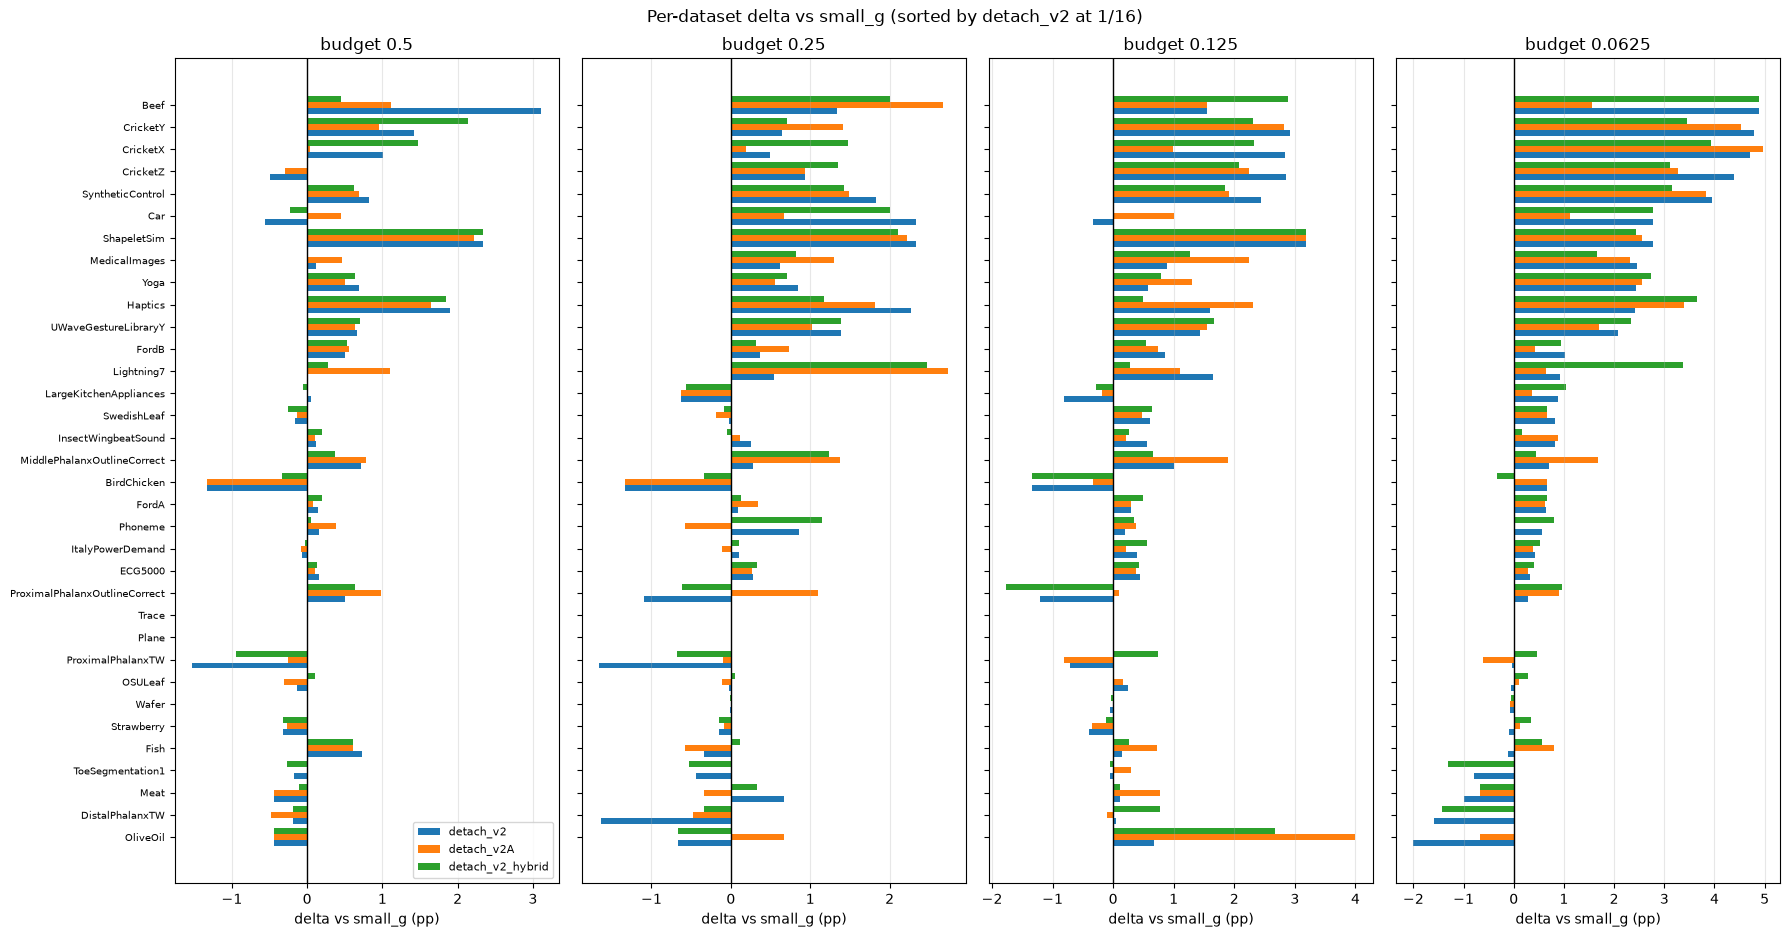

In [27]:
# ---- 8.6 Per-dataset delta vs small_g (pp), sorted by v2's delta at 1/16, and figure ----
PD_METHODS = ["detach_v2", "detach_v2A", "detach_v2_hybrid"]
pdt = pd.DataFrame({(m, b): delta_sg(ACC, m, b) for m in PD_METHODS for b in BUDGETS})
pdt.columns = pd.MultiIndex.from_tuples(pdt.columns, names=["method", "budget"])
pdt = pdt.sort_values(("detach_v2", 0.0625))
meta_ds = runs.groupby("dataset")[["n_train", "length", "n_classes"]].first()
display(pdt.join(pd.concat({"meta": meta_ds}, axis=1)).round(2))

fig, axes = plt.subplots(1, len(BUDGETS), figsize=(18, max(6, 0.28 * len(pdt))), sharey=True)
y = np.arange(len(pdt))
for ax, b in zip(axes, BUDGETS):
    for j, m in enumerate(PD_METHODS):
        ax.barh(y + (j - 1) * 0.27, pdt[(m, b)].to_numpy(), height=0.27, label=m)
    ax.axvline(0, color="black", lw=1)
    ax.set_title(f"budget {b}"); ax.set_xlabel("delta vs small_g (pp)"); ax.grid(axis="x", alpha=0.3)
axes[0].set_yticks(y, pdt.index, fontsize=7); axes[0].legend(fontsize=8)
fig.suptitle("Per-dataset delta vs small_g (sorted by detach_v2 at 1/16)")
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}per_dataset_delta.png", dpi=150, bbox_inches="tight")
plt.show()

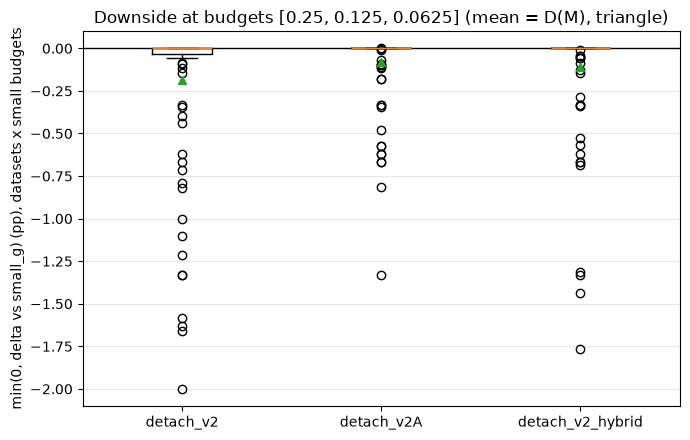

share of (dataset, small budget) cells with a loss to small_g: {'detach_v2': 0.284, 'detach_v2A': 0.225, 'detach_v2_hybrid': 0.216}


In [28]:
# ---- 8.7 Downside figure: per-dataset min(0, delta vs small_g) at the small budgets ----
down = {m: np.minimum(0.0, pd.concat([delta_sg(ACC, m, b) for b in SMALL_BUDGETS], axis=1)).to_numpy().ravel()
        for m in PD_METHODS}
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot(list(down.values()), showmeans=True)
ax.set_xticks(range(1, len(down) + 1), list(down.keys()))
ax.axhline(0, color="black", lw=1)
ax.set_ylabel("min(0, delta vs small_g) (pp), datasets x small budgets")
ax.set_title(f"Downside at budgets {SMALL_BUDGETS} (mean = D(M), triangle)")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(FIG_DIR / f"{FIG_PREFIX}downside.png", dpi=150, bbox_inches="tight")
plt.show()
print("share of (dataset, small budget) cells with a loss to small_g:",
      {m: round(float((v < 0).mean()), 3) for m, v in down.items()})

### 8.8 Secondary view: all 40 development datasets

**Secondary; the 6 pilot datasets were selected as extremes.** The same decision quantities on the 34 datasets above plus the 6 pilot datasets from `detach_fix_pilot_runs.csv`, computed the same way. This does **not** change the decision.

In [29]:
pil = pd.read_csv(PILOT_RUNS_CSV)
pil["budget"] = pil["budget"].round(6)
pil = pil[pil["method"].isin(["full", "small_g"] + DECISION_METHODS) & pil["dataset"].isin(PILOT_DATASETS)]
pil_complete = [d for d in PILOT_DATASETS if pil[pil["dataset"] == d]["resample"].nunique() == 5]
ACC40 = pd.concat([ACC[[c for c in ACC.columns if c[0] in ["full", "small_g"] + DECISION_METHODS]],
                   per_dataset_acc(pil[pil["dataset"].isin(pil_complete)])])
print(f"secondary view on {len(ACC40)} datasets ({len(DS_USED)} run here + {len(pil_complete)} pilot)")
Q40 = decision_quantities(ACC40)
display(pd.DataFrame(Q40).T.round(3))
t40, choice40, why40 = apply_rule(Q40)
display(t40.round(3))
print(f"(secondary, for information only) the rule applied to {len(ACC40)} datasets would give: {choice40} ({why40})")
rows = []
for m in DECISION_METHODS:
    worst = pd.concat([delta_sg(ACC40, m, b) for b in SMALL_BUDGETS], axis=1).min(axis=1)
    rows += [{"method": m, "threshold_pp": thr, "n_datasets": int((worst < thr).sum()),
              "datasets": ", ".join(sorted(worst[worst < thr].index))} for thr in [-2, -5]]
with pd.option_context("display.max_colwidth", 400):
    display(pd.DataFrame(rows))

secondary view on 40 datasets (34 run here + 6 pilot)


,D,A16,O,n_datasets
detach_v2,-0.441,1.315,0.000,40.0
detach_v2A,-0.227,1.267,0.213,40.0
detach_v2_hybrid,-0.299,1.388,0.163,40.0


,D(F),D(v2),D(F)-D(v2),A16(F),A16(v2),A16(F)-A16(v2),O(F),reduces_downside,keeps_1_16_advantage,not_worse_overall,eligible
fix,,,,,,,,,,,
detach_v2A,-0.227,-0.441,0.214,1.267,1.315,-0.048,0.213,True,True,True,True
detach_v2_hybrid,-0.299,-0.441,0.142,1.388,1.315,0.073,0.163,True,True,True,True


(secondary, for information only) the rule applied to 40 datasets would give: adopt v2_hybrid (both eligible; downside improvements +0.214 vs +0.142 differ by < 0.10 pp)


,method,threshold_pp,n_datasets,datasets
0,detach_v2,-2,2,"MiddlePhalanxOutlineAgeGroup, ScreenType"
1,detach_v2,-5,1,MiddlePhalanxOutlineAgeGroup
2,detach_v2A,-2,2,"MiddlePhalanxOutlineAgeGroup, ScreenType"
3,detach_v2A,-5,0,
4,detach_v2_hybrid,-2,1,MiddlePhalanxOutlineAgeGroup
5,detach_v2_hybrid,-5,1,MiddlePhalanxOutlineAgeGroup


In [30]:
# ---- 8.9 Cost: path wall-clock seconds (all threads); the hybrid adds no path time ----
PATH_METHODS = (["detach_v1"] if INCLUDE_V1 else []) + ["detach_v2", "detach_v2A"]
ps = (runs[runs["method"].isin(PATH_METHODS)].groupby(["dataset", "resample", "method"])["path_s"].first().unstack())
cost = pd.concat({"median_s": ps.groupby(level="dataset").median(), "total_s": ps.groupby(level="dataset").sum()}, axis=1)
cost[("ratio", "v2A/v2 (median of splits)")] = (ps["detach_v2A"] / ps["detach_v2"]).groupby(level="dataset").median()
cost = cost.reindex(DS_USED)
display(cost.round(2))
print(f"total path seconds: " + ", ".join(f"{m} {ps[m].sum():.0f}s" for m in PATH_METHODS)
      + f" | v2A/v2 ratio of totals {ps['detach_v2A'].sum() / ps['detach_v2'].sum():.2f}")
print(f"total wall-clock of the completed pairs: {runs.groupby(['dataset', 'resample'])['pair_s'].first().sum() / 3600:.2f} h")

median_s              total_s             \
method                        detach_v2 detach_v2A detach_v2 detach_v2A   
dataset                                                                   
ItalyPowerDemand                   0.34       1.09      1.77       5.70   
ShapeletSim                        0.28       0.97      1.41       4.83   
BirdChicken                        0.28       0.99      1.41       4.85   
ToeSegmentation1                   0.35       1.14      1.75       5.70   
Beef                               0.31       1.13      1.58       5.65   
Plane                              0.53       1.53      2.65       7.71   
OliveOil                           0.34       1.17      1.71       5.78   
SyntheticControl                   1.60       3.20      8.00      16.03   
Lightning7                         0.45       1.41      2.27       7.10   
Meat                               0.42       1.38      2.13       7.17   
Trace                              0.64       1.78      3.14       8.88   
DistalPhalanxTW                    3.20       5.57     15.89      27.90   
ProximalPhalanxTW                  3.03       5.20     15.13      26.82   
Car                                0.43       1.43      2.17       7.20   
MedicalImages                      2.92       4.98     14.64      24.91   
MiddlePhalanxOutlineCorrect        6.11      10.48     30.62      52.51   
ProximalPhalanxOutlineCorrect      5.85      10.22     29.15      51.10   
InsectWingbeatSound                1.12       2.69      5.60      13.45   
SwedishLeaf                        4.70       7.14     24.29      36.38   
ECG5000                            5.19       7.04     25.90      35.29   
Fish                               0.90       2.26      4.49      11.30   
OSULeaf                            1.03       2.53      5.12      12.63   
CricketX                           3.47       6.09     17.24      30.46   
CricketY                           3.17       5.98     15.94      29.90   
CricketZ                           3.23       5.95     16.11      29.68   
Yoga                               1.85       4.44      9.29      22.24   
Strawberry                         6.51      10.89     32.43      54.12   
Wafer                             18.24      26.77     91.24     133.25   
Haptics                            0.89       2.27      4.42      11.43   
Phoneme                            1.59       4.42      8.05      22.38   
LargeKitchenAppliances             2.89       5.15     14.62      25.97   
UWaveGestureLibraryY              16.39      25.29     83.39     125.92   
FordA                            355.78     474.54   1783.37    2377.16   
FordB                            366.30     490.46   1827.26    2446.45   

                                                  ratio  
method                        v2A/v2 (median of splits)  
dataset                                                  
ItalyPowerDemand                                   3.23  
ShapeletSim                                        3.52  
BirdChicken                                        3.46  
ToeSegmentation1                                   3.25  
Beef                                               3.64  
Plane                                              2.91  
OliveOil                                           3.39  
SyntheticControl                                   2.05  
Lightning7                                         3.09  
Meat                                               3.40  
Trace                                              2.88  
DistalPhalanxTW                                    1.77  
ProximalPhalanxTW                                  1.75  
Car                                                3.32  
MedicalImages                                      1.69  
MiddlePhalanxOutlineCorrect                        1.74  
ProximalPhalanxOutlineCorrect                      1.75  
InsectWingbeatSound                                2.41  
SwedishLeaf                          

total path seconds: detach_v2 4104s, detach_v2A 5688s | v2A/v2 ratio of totals 1.39
total wall-clock of the completed pairs: 4.32 h


In [31]:
# ---- 8.10 Structure: block coverage, minimum groups per block, share of kept groups on diff(X) ----
struct = (runs[runs["method"].isin(["small_g"] + PRUNED_METHODS)].groupby(["method", "budget"])
          .agg(block_coverage_mean=("block_coverage", "mean"), block_coverage_min=("block_coverage", "min"),
               min_groups_per_block_mean=("min_groups_per_block", "mean"),
               min_groups_per_block_min=("min_groups_per_block", "min")))
diff_share = []
for chunk in pd.read_csv(KEPT_CSV, usecols=["dataset", "resample", "method", "budget", "diff_index", "kept"],
                         chunksize=2_000_000):
    chunk = chunk[chunk["kept"] & chunk["dataset"].isin(DS_USED)]
    diff_share.append(chunk.groupby(["method", "budget"])["diff_index"].agg(["sum", "count"]))
ds_ = pd.concat(diff_share).groupby(level=[0, 1]).sum()
ds_.index = ds_.index.set_levels(ds_.index.levels[1].round(6), level=1)
struct["diff_share_kept"] = (ds_["sum"] / ds_["count"]).reindex(struct.index)
struct.loc[struct.index.get_level_values(0) == "small_g", "diff_share_kept"] = 0.5   # by construction
display(struct.round(3))

print("Checks logged in this session:")
for name, res in CHECKS:
    print(f"  {res}: {name}")

block_coverage_mean  block_coverage_min  \
method           budget                                            
detach_v2        0.0625                0.729               0.333   
                 0.1250                0.901               0.500   
                 0.2500                0.974               0.643   
                 0.5000                0.996               0.857   
detach_v2A       0.0625                0.724               0.250   
                 0.1250                0.884               0.417   
                 0.2500                0.963               0.500   
                 0.5000                0.995               0.857   
detach_v2_hybrid 0.0625                1.000               1.000   
                 0.1250                1.000               1.000   
                 0.2500                1.000               1.000   
                 0.5000                1.000               1.000   
small_g          0.0625                1.000               1.000   
                 0.1250                1.000               1.000   
                 0.2500                1.000               1.000   
                 0.5000                1.000               1.000   

                         min_groups_per_block_mean  min_groups_per_block_min  \
method           budget                                                        
detach_v2        0.0625                      0.059                         0   
                 0.1250                      0.512                         0   
                 0.2500                      1.900                         0   
                 0.5000                      5.988                         0   
detach_v2A       0.0625                      0.024                         0   
                 0.1250                      0.412                         0   
                 0.2500                      1.588                         0   
                 0.5000                      4.876                         0   
detach_v2_hybrid 0.0625                      1.006                         1   
                 0.1250                      2.059                         2   
                 0.2500                      4.512                         4   
                 0.5000                      9.900                         8   
small_g          0.0625                      2.000                         2   
                 0.1250                      4.000                         4   
                 0.2500                      8.000                         8   
                 0.5000                     16.000                        16   

                         diff_share_kept  
method           budget                   
detach_v2        0.0625            0.354  
                 0.1250            0.397  
                 0.2500            0.442  
                 0.5000            0.480  
detach_v2A       0.0625            0.367  
                 0.1250            0.410  
                 0.2500            0.453  
                 0.5000            0.491  
detach_v2_hybrid 0.0625            0.430  
                 0.1250            0.427  
                 0.2500            0.449  
                 0.5000            0.472  
small_g          0.0625            0.500  
                 0.1250            0.500  
                 0.2500            0.500  
                 0.5000            0.500

Checks logged in this session:
  PASS: Check 1: dataset lists - 34 run datasets = 40 development - 6 pilot; none held out
  PASS: official Hydra: divisor = 2, h = g//2, groups = num_dilations*g, dilations independent of g
  PASS: Check 7: detach_v2_path and detach_path take training arrays only (v2 parameters: ['Xtr_scaled', 'ytr', 'group_cols', 'budgets', 'B', 'frac', 'alphas', 'seed_base'])
  PASS: Check 7: hybrid_select takes a ranking and block ids only (no data arrays)
  PASS: Check 4 (synthetic): hybrid gives exactly N, includes the top N//2, >= quota per block, handles the shortfall case, is deterministic, matches an independent implementation; quota = 0 -> global top N
  PASS: pilot Test 1 (all groups kept == official) on ECG200 + Beef
  PASS: pilot Tests 2+3 (random masks == kept columns; counts) on ECG200 + Beef
  PASS: pilot Test 4 (SparseScaler subset) on ECG200 + Beef
  PASS: pipeline with authors' grid reproduces Notebook 1 on ECG200 seed 0 (0.8700)
  PASS: Check 2: v2 ge